# PS4 — Statistical Machine Translation: English → German (News / Media)
**AIML ZG521 NLP Applications · Assignment 2 · Part 1 (Programming)**

| Problem Statement | Group | Student name | Student ID |
|---|---|---|---|
| PS 4 | `<Group No>` | Devdeep Dasgupta | `<BITS ID>` |
| | | Ahamed Imthias | `<BITS ID>` |
| | | Vishvajith | `<BITS ID>` |

### Problem statement
A news agency wants to translate wire stories and headlines from **English to German** to syndicate content to
European partners. We build (1) IBM Model 1 word alignment from scratch, (2) a phrase-based SMT system with an
n-gram language model and our own decoder, and (3) compare it against a pretrained neural MT model. We evaluate
BLEU, adequacy, fluency, OOV handling, latency and robustness on the domain's stress-test focus: headlines with
dropped articles and verbs, long German compounds, named entities and quotations, and date and place expressions.

### Notebook structure
| Section | Content |
|---|---|
| 0 | Configuration (seed, sizes, model settings) |
| A | Corpus collection, cleaning, tokenization, split and analysis; evaluation and stress sets |
| B | IBM Model 1 with EM, written from scratch in both directions: convergence, top-5 tables, alignment heatmaps, limitations |
| C | Phrase-based SMT: symmetrization, phrase extraction, phrase table, Kneser–Ney trigram LM, **own stack decoder**, beam sweep, examples |
| D | Pretrained NMT (`Helsinki-NLP/opus-mt-en-de`) and the SMT-vs-NMT comparison table and charts |
| E | BLEU written from scratch (validated against sacreBLEU and NLTK), evaluation-set results, human ratings, stress-test error analysis |
| F | Reflection and deployment recommendation |
| Ref | References |

> **Notation (noisy channel).** The assignment's decoder score is
> `score(e) = λ1·log P(f|e) + λ2·log P_LM(e)`. Here **e is the German output and f the English input**, so the
> translation model in the decoder is **P(English | German)** and the language model is a German LM.

No API keys, passwords or access tokens are used anywhere; the dataset and the NMT model are public.

## 0. Configuration

In [1]:
import os, re, json, math, time, random, logging, unicodedata, warnings
from collections import Counter, defaultdict
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sacremoses import MosesTokenizer, MosesDetokenizer
import sacrebleu

warnings.filterwarnings('ignore')
logging.getLogger('sacrebleu').setLevel(logging.ERROR)   # silence sacreBLEU tokenization hints
os.environ['HF_HUB_DISABLE_SYMLINKS_WARNING'] = '1'
os.environ['HF_HUB_VERBOSITY'] = 'error'      # public model/dataset only: no HF token needed or used

# Shared configuration -- Member 2 uses the same values.
CONFIG = dict(
    SEED=42,
    POOL_SIZE=40_000,          # random pool drawn from the cleaned corpus before length filtering
    N_TRAIN=10_000, N_TEST=500, N_LM_HELDOUT=500,
    MIN_LEN=1, MAX_LEN=30,     # tokens, applied to both sides
    MAX_LEN_RATIO=2.0,         # max(len_en, len_de) / min(len_en, len_de)
    EM_ITERS=10, MAX_PHRASE_LEN=4, LM_ORDER=3, BEAMS=[1, 2, 5, 10],   # used by Parts B/C
    NMT_MODEL='Helsinki-NLP/opus-mt-en-de', NMT_BEAMS=4, NMT_BATCH=16,
)
# Part C settings.
SMT = dict(SYMMETRIZATION='grow-diag-final', TABLE_LIMIT=20, DISTORTION_LIMIT=4,
           KN_DISCOUNT=0.75, N_DEV=300, OOV_PENALTY=-10.0)
SEED = CONFIG['SEED']
random.seed(SEED); np.random.seed(SEED)

ROOT = Path.cwd()
DATA, OUT = ROOT / 'data', ROOT / 'outputs'
FIG = OUT / 'figures'
for d in (DATA, OUT, FIG):
    d.mkdir(exist_ok=True)

sns.set_theme(style='whitegrid')
pd.set_option('display.max_colwidth', 110)
CONFIG

{'SEED': 42,
 'POOL_SIZE': 40000,
 'N_TRAIN': 10000,
 'N_TEST': 500,
 'N_LM_HELDOUT': 500,
 'MIN_LEN': 1,
 'MAX_LEN': 30,
 'MAX_LEN_RATIO': 2.0,
 'EM_ITERS': 10,
 'MAX_PHRASE_LEN': 4,
 'LM_ORDER': 3,
 'BEAMS': [1, 2, 5, 10],
 'NMT_MODEL': 'Helsinki-NLP/opus-mt-en-de',
 'NMT_BEAMS': 4,
 'NMT_BATCH': 16}

## Part A — Corpus collection, preprocessing and analysis

### A.1 Business scenario and target users
- **Scenario.** A news agency publishes English wire copy (breaking news, headlines, business and political
  reporting) and syndicates it to partner outlets in Germany, Austria and Switzerland. Translation must be fast
  (wire speed), faithful on facts (names, numbers, dates, places, quotations) and fluent enough for light
  post-editing.
- **Target users.** (i) Desk editors / post-editors at the agency who review machine output before release;
  (ii) German-language partner newsrooms consuming the feed; (iii) indirectly, their readers.
- **Implication for MT.** Errors on named entities, numbers and negation are far more costly than stylistic
  imperfections; headlines use a telegraphic register (dropped articles and verbs) that general corpora rarely
  contain.

### A.2 Corpus source
We use the **News Commentary** English–German parallel corpus (WMT training data, distributed via OPUS and
the Hugging Face hub as `Helsinki-NLP/news_commentary`, config `de-en`; ~223k sentence pairs; Tiedemann 2012).
It is the closest freely available match to the news domain among the suggested corpora: it contains
political and economic commentary (Project Syndicate) with article titles. **Europarl** was considered but
rejected as the primary source because parliamentary speech is a larger domain mismatch for wire news.
We sample a 10,000-pair training set (within the required 5k–20k) plus 500 held-out test pairs and 500
held-out German sentences for language-model perplexity.

In [2]:
from datasets import load_dataset

nc = load_dataset('Helsinki-NLP/news_commentary', 'de-en', split='train')
raw = pd.DataFrame([{'en': t['en'], 'de': t['de']} for t in nc['translation']])
print(f'News Commentary de-en: {len(raw):,} sentence pairs')
raw.sample(5, random_state=SEED)

README.md:   0%|          | 0.00/26.9k [00:00<?, ?B/s]

de-en/train-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 45.2MB            

de-en/train-00000-of-00001.parquet: downloading bytes:           |  0.00B            

Generating train split:   0%|          | 0/223153 [00:00<?, ? examples/s]

News Commentary de-en: 223,153 sentence pairs


,en,de
158208,"This same lack of confidence is behind the potentially explosive situations in Algeria, Tunisia, and even ...","Derselbe Mangel an Selbstvertrauen ist die Grundlage für die potenziell explosive Lage in Algerien, Tunesi..."
192948,"For example, the presence of mirror neurons in Broca's region suggests that human language co-evolved with...","Zum Beispiel deutet das Vorhandensein von Spiegelneuronen in der Broca Region daraufhin, dass sich die men..."
53244,Alternative approaches are being tested and must be carefully reviewed.,Alternative Ansätze werden getestet und müssen sorgfältig überprüft werden.
40766,Back to Socialism,Zurück zum Sozialismus
58241,The goal is not to absorb shocks but to reduce income gaps across regions.,"Das Ziel besteht hier nicht darin, Erschütterungen aufzufangen, sondern Einkommensdifferenzen zwischen den..."


### A.3 Cleaning, normalization and tokenization
Pipeline (each step's effect is shown in the table below):
1. **Normalization** — Unicode NFC, collapse whitespace (kept with original casing as the *raw* text used by
   NMT and sacreBLEU).
2. **Cleaning** — drop pairs with an empty side, segments without letters, untranslated pairs (EN == DE) and
   duplicate English sources (prevents train/test leakage of repeated titles).
3. **Sampling** — a seeded random pool of 40,000 pairs (tokenizing all 223k is unnecessary for a 10k sample).
4. **Tokenization** — typographic quotes/dashes mapped to ASCII (German „…“ and English “…” become the same
   token), Moses tokenizer with language-specific rules (`sacremoses`, `en`/`de`), then lowercasing.
   German compounds are deliberately *not* split — this is one of the stress-test phenomena.
5. **Length filtering** — 1–30 tokens on both sides and length ratio ≤ 2 (removes misaligned pairs and keeps
   IBM Model 1 EM tractable, as its cost grows with |e|·|f| per sentence pair).

`preprocess(text, lang)` is the single tokenization function shared with Member 2 (Parts B, C, E).

In [3]:
QUOTE_MAP = str.maketrans({'„': '"', '“': '"', '”': '"', '«': '"', '»': '"',
                           '‚': "'", '‘': "'", '’': "'", '–': '-', '—': '-'})
_MOSES = {'en': MosesTokenizer(lang='en'), 'de': MosesTokenizer(lang='de')}

def normalize(text):
    """Unicode NFC + collapsed whitespace; casing and punctuation are kept (raw text)."""
    return re.sub(r'\s+', ' ', unicodedata.normalize('NFC', text)).strip()

def preprocess(text, lang):
    """normalize -> ASCII quotes/dashes -> Moses tokenization -> lowercase. Returns a list of tokens."""
    text = normalize(text).translate(QUOTE_MAP)
    return [tok.lower() for tok in _MOSES[lang].tokenize(text, escape=False)]

print(preprocess('„Wir werden nicht nachgeben“, sagte Scholz am 3. Oktober in Berlin.', 'de'))
print(preprocess("The Fed's “dovish” turn won't last, analysts say.", 'en'))

['"', 'wir', 'werden', 'nicht', 'nachgeben', '"', ',', 'sagte', 'scholz', 'am', '3.', 'oktober', 'in', 'berlin', '.']
['the', 'fed', "'s", '"', 'dovish', '"', 'turn', 'won', "'t", 'last', ',', 'analysts', 'say', '.']


In [4]:
C = CONFIG
steps = [('raw pairs', len(raw))]

df = pd.DataFrame({'en': raw.en.map(normalize), 'de': raw.de.map(normalize)})
df = df[(df.en != '') & (df.de != '')];                                       steps.append(('drop empty side', len(df)))
df = df[df.en.str.contains('[A-Za-z]') & df.de.str.contains('[A-Za-zÄÖÜäöüß]')]; steps.append(('drop segments without letters', len(df)))
df = df[df.en.str.lower() != df.de.str.lower()];                              steps.append(('drop untranslated (EN == DE)', len(df)))
df = df.drop_duplicates(subset='en');                                         steps.append(('drop duplicate English sources', len(df)))

pool = df.sample(n=C['POOL_SIZE'], random_state=SEED).copy();                 steps.append(('seeded random pool', len(pool)))
pool['en_tok'] = pool.en.map(lambda s: preprocess(s, 'en'))
pool['de_tok'] = pool.de.map(lambda s: preprocess(s, 'de'))
pool['len_en'], pool['len_de'] = pool.en_tok.map(len), pool.de_tok.map(len)

keep = pool[pool.len_en.between(C['MIN_LEN'], C['MAX_LEN']) & pool.len_de.between(C['MIN_LEN'], C['MAX_LEN'])]
steps.append((f"length {C['MIN_LEN']}-{C['MAX_LEN']} tokens (both sides)", len(keep)))
ratio = keep[['len_en', 'len_de']].max(axis=1) / keep[['len_en', 'len_de']].min(axis=1)
keep = keep[ratio <= C['MAX_LEN_RATIO']];                                     steps.append((f"length ratio <= {C['MAX_LEN_RATIO']}", len(keep)))

pd.DataFrame(steps, columns=['step', 'pairs remaining'])

,step,pairs remaining
0,raw pairs,223153
1,drop empty side,223153
2,drop segments without letters,221705
3,drop untranslated (EN == DE),221567
4,drop duplicate English sources,220982
5,seeded random pool,40000
6,length 1-30 tokens (both sides),26134
7,length ratio <= 2.0,26049


### A.4 Train / test / LM-held-out split and export
The filtered pool is shuffled once with the fixed seed and cut into disjoint sets. Files are written to
`data/` in the format agreed with Member 2 (UTF-8, one sentence per line, EN/DE line-aligned).

In [5]:
keep = keep.sample(frac=1, random_state=SEED).reset_index(drop=True)
n_te, n_lm, n_tr = C['N_TEST'], C['N_LM_HELDOUT'], C['N_TRAIN']
test  = keep.iloc[:n_te].reset_index(drop=True)
lm_ho = keep.iloc[n_te:n_te + n_lm].reset_index(drop=True)
train = keep.iloc[n_te + n_lm:n_te + n_lm + n_tr].reset_index(drop=True)
assert len(train) == n_tr and len(test) == n_te and len(lm_ho) == n_lm
assert not set(train.en) & set(test.en), 'train/test overlap'

def write_lines(path, lines):
    path.write_text('\n'.join(lines) + '\n', encoding='utf-8')

for name, part in [('train', train), ('test', test)]:
    write_lines(DATA / f'{name}.tok.en', [' '.join(t) for t in part.en_tok])
    write_lines(DATA / f'{name}.tok.de', [' '.join(t) for t in part.de_tok])
write_lines(DATA / 'test.raw.en', test.en.tolist())
write_lines(DATA / 'test.raw.de', test.de.tolist())
write_lines(DATA / 'lm_heldout.tok.de', [' '.join(t) for t in lm_ho.de_tok])

for f in sorted(DATA.glob('*.??')):
    print(f'{f.name:22s} {sum(1 for _ in f.open(encoding="utf-8")):>6,} lines')

README.md                  19 lines
lm_heldout.tok.de         500 lines
test.raw.de               500 lines
test.raw.en               500 lines
test.tok.de               500 lines
test.tok.en               500 lines
train.tok.de           10,000 lines
train.tok.en           10,000 lines


### A.5 Corpus analysis

In [6]:
train_vocab = {l: Counter(t for s in train[f'{l}_tok'] for t in s) for l in ('en', 'de')}

def corpus_stats(lang):
    v = train_vocab[lang]
    n_tok = sum(v.values())
    lens = train[f'len_{lang}']
    test_toks = [t for s in test[f'{lang}_tok'] for t in s]
    oov = [t for t in test_toks if t not in v]
    return {
        'sentences (train)': len(train),
        'tokens (train)': n_tok,
        'vocabulary size (types)': len(v),
        'type/token ratio': round(len(v) / n_tok, 4),
        'singleton types (%)': round(100 * sum(c == 1 for c in v.values()) / len(v), 1),
        'avg sentence length': round(lens.mean(), 2),
        'median / max length': f'{int(lens.median())} / {lens.max()}',
        'test OOV token rate (%)': round(100 * len(oov) / len(test_toks), 2),
        'test OOV types': len(set(oov)),
    }

stats = pd.DataFrame({'English': corpus_stats('en'), 'German': corpus_stats('de')})
stats

,English,German
sentences (train),10000,10000
tokens (train),178274,179687
vocabulary size (types),15192,23197
type/token ratio,0.0852,0.1291
singleton types (%),48.3,59.6
avg sentence length,17.83,17.97
median / max length,18 / 30,18 / 30
test OOV token rate (%),3.93,7.49
test OOV types,352,671


In [7]:
def is_headline(s):
    return not s.rstrip().endswith(('.', '?', '!', '"', '“', '”', ':'))

head_share = 100 * train.en.map(is_headline).mean()
de_long_compounds = [w for w in train_vocab['de'] if w.isalpha() and len(w) >= 15]
print(f'Average DE/EN length ratio        : {(train.len_de / train.len_en).mean():.3f}')
print(f'Headline-like segments (train, EN): {head_share:.1f}%  (no sentence-final punctuation)')
print(f'German types with >= 15 letters   : {len(de_long_compounds):,} '
      f'({100 * len(de_long_compounds) / len(train_vocab["de"]):.1f}% of DE vocabulary)')
print('Examples:', ', '.join(sorted(de_long_compounds, key=len, reverse=True)[:8]))
print('Most frequent EN:', [w for w, _ in train_vocab['en'].most_common(15)])
print('Most frequent DE:', [w for w, _ in train_vocab['de'].most_common(15)])

Average DE/EN length ratio        : 1.022
Headline-like segments (train, EN): 4.7%  (no sentence-final punctuation)
German types with >= 15 letters   : 3,401 (14.7% of DE vocabulary)
Examples: telekommunikationsgesellschaften, leistungsbilanzungleichgewichte, spitzenrefinanzierungsfazilität, handelsliberalisierungsabkommen, fremdwährungsverbindlichkeiten, finanzdienstleistungsindustrie, nichtregierungsorganisationen, energieversorgungsunternehmen
Most frequent EN: ['the', '.', ',', 'of', 'to', 'and', 'in', 'a', 'is', 'that', "'s", 'for', 'it', 'be', 'are']
Most frequent DE: ['.', ',', 'die', 'der', 'und', 'in', 'zu', 'ist', 'den', 'das', 'eine', 'von', 'sich', 'nicht', 'es']


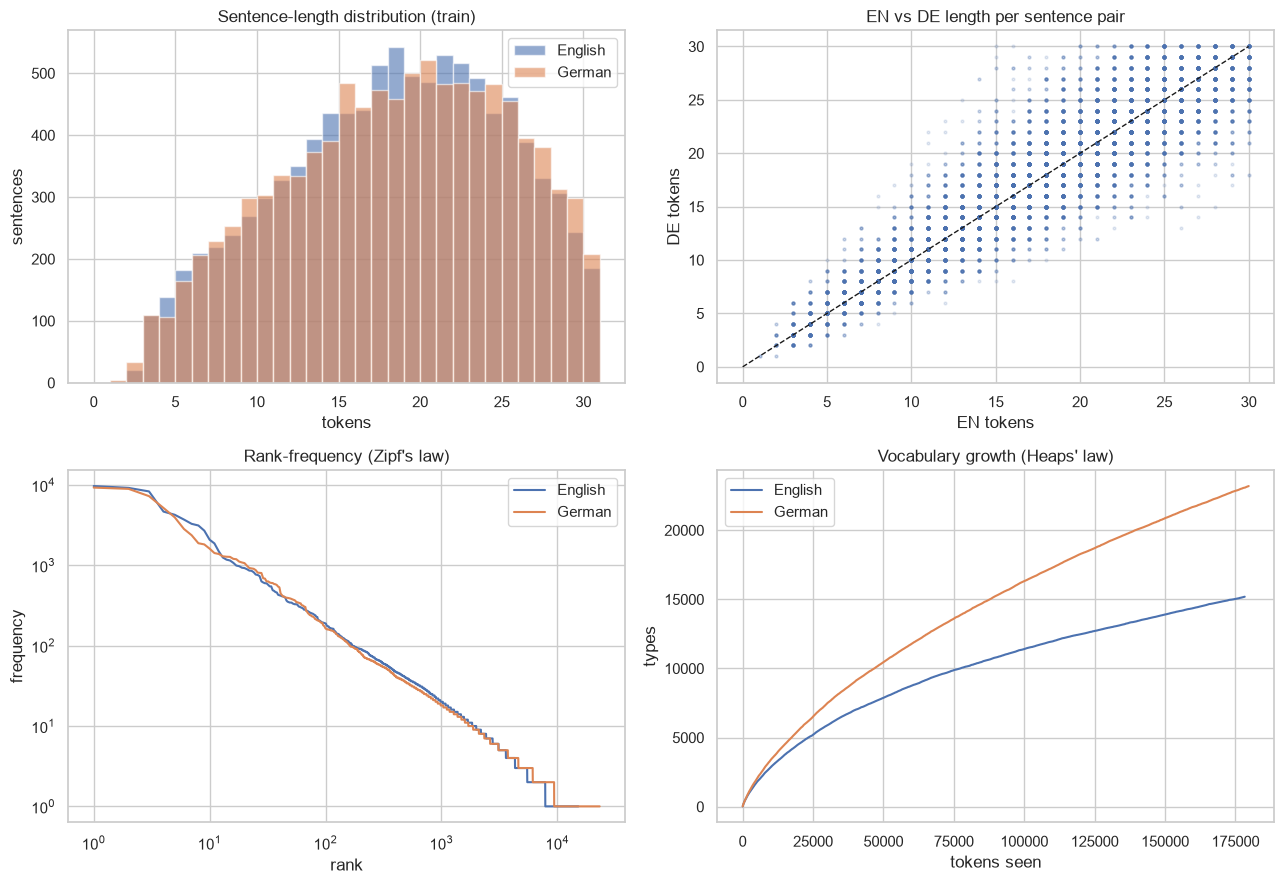

In [8]:
fig, ax = plt.subplots(2, 2, figsize=(13, 9))
bins = np.arange(0, C['MAX_LEN'] + 2)
ax[0, 0].hist(train.len_en, bins=bins, alpha=.6, label='English')
ax[0, 0].hist(train.len_de, bins=bins, alpha=.6, label='German')
ax[0, 0].set(title='Sentence-length distribution (train)', xlabel='tokens', ylabel='sentences'); ax[0, 0].legend()

ax[0, 1].scatter(train.len_en, train.len_de, s=4, alpha=.15)
ax[0, 1].plot([0, 30], [0, 30], 'k--', lw=1)
ax[0, 1].set(title='EN vs DE length per sentence pair', xlabel='EN tokens', ylabel='DE tokens')

for lang, label in (('en', 'English'), ('de', 'German')):
    freqs = np.array(sorted(train_vocab[lang].values(), reverse=True))
    ax[1, 0].loglog(np.arange(1, len(freqs) + 1), freqs, label=label)
    seen, growth, n = set(), [], 0
    for s in train[f'{lang}_tok']:
        seen.update(s); n += len(s); growth.append((n, len(seen)))
    g = np.array(growth); ax[1, 1].plot(g[:, 0], g[:, 1], label=label)
ax[1, 0].set(title="Rank-frequency (Zipf's law)", xlabel='rank', ylabel='frequency'); ax[1, 0].legend()
ax[1, 1].set(title='Vocabulary growth (Heaps\' law)', xlabel='tokens seen', ylabel='types'); ax[1, 1].legend()
plt.tight_layout(); plt.savefig(FIG / 'A_corpus_analysis.png', dpi=120); plt.show()

### A.6 Observations, domain match and limitations
- **Size after cleaning.** 223,153 raw pairs → 220,982 after cleaning; from the 40k pool, 26,049 pairs (65%)
  pass the length filters, from which 10,000 train / 500 test / 500 LM-held-out are drawn.
- **German is lexically much sparser.** With almost identical token counts (~178k EN vs ~180k DE), German has
  **1.5× more types** (≈23.2k vs ≈15.2k), a higher type/token ratio (0.129 vs 0.085) and ~60% singleton types.
  Inflection (case, gender, number) and compounding split the probability mass, so many German words are seen
  once and IBM Model 1 / phrase-table estimates for them will be unreliable.
- **Compounds.** About 15% of German types have ≥ 15 letters (e.g. *leistungsbilanzungleichgewichte*,
  *nichtregierungsorganisationen*). Each aligns to several English words — a one-to-many pattern that IBM
  Model 1 cannot express (no fertility) and that phrase extraction only partially recovers.
- **OOV.** About 3.9% of English and 7.5% of German test tokens are unseen in training, and **233 of 500 test
  sentences contain at least one English OOV**, which a word/phrase-based system can only copy or drop.
  The vocabulary-growth curve has not flattened at 10k pairs, so more data would keep reducing OOV.
- **Length.** Average lengths are ~18 tokens on both sides (DE/EN ratio ≈ 1.02), indicating clean
  sentence alignment.
- **Domain match / mismatch.** News Commentary is *opinion and analysis* on economics and politics, not wire
  news: long analytical sentences, only ~5% headline-like segments, and little event vocabulary (police,
  storms, strikes, dates). We therefore expect the SMT system to handle economic/political terminology
  reasonably and to struggle on telegraphic headlines and breaking-news reporting — exactly the PS4 stress
  focus. A 10k-pair corpus is also tiny compared with the millions of pairs behind production SMT/NMT, so
  absolute SMT quality will be low; the pretrained NMT model has seen far more (and partly overlapping) data.
- **Limitations.** (i) Commentary register rather than wire copy; (ii) sentences longer than 30 tokens are
  excluded, although wire stories often contain long sentences; (iii) lowercasing removes German noun
  capitalization and named-entity cues; (iv) residual misalignments in the crawled corpus; (v) a random
  10k sample rather than the full corpus, chosen to keep from-scratch EM tractable.

In [9]:
readme = f'''# data/ — PS4 EN→DE parallel data (generated by A_D_member1.ipynb)

Source: News Commentary EN–DE (WMT training data), loaded from the Hugging Face hub
`Helsinki-NLP/news_commentary` (config `de-en`, {len(raw):,} pairs); also distributed via OPUS
(https://opus.nlpl.eu/datasets/News-Commentary). Licence: see the OPUS/WMT corpus page (research use).
Citation: J. Tiedemann (2012), Parallel Data, Tools and Interfaces in OPUS, LREC.

Pipeline: NFC + whitespace normalization; drop empty / letter-less / untranslated pairs; dedupe English side;
seeded pool of {C["POOL_SIZE"]:,}; ASCII quotes/dashes; Moses tokenizer (sacremoses, en/de, escape=False);
lowercase; keep {C["MIN_LEN"]}-{C["MAX_LEN"]} tokens per side and length ratio <= {C["MAX_LEN_RATIO"]}; seed {SEED}.

| file | lines | content |
|---|---|---|
| train.tok.en / train.tok.de | {len(train):,} | tokenized, lowercased training pairs |
| test.tok.en / test.tok.de | {len(test):,} | held-out pairs, same preprocessing |
| test.raw.en / test.raw.de | {len(test):,} | same test pairs, original casing, untokenized (NMT input, sacreBLEU refs) |
| lm_heldout.tok.de | {len(lm_ho):,} | German-only held-out sentences for LM perplexity |
| eval_set.csv | see file | 15-sentence evaluation set (id, category, en, de_ref, source) |
| stress_set.csv | see file | robustness stress set (id, phenomenon, en, de_ref, news_focus) |
'''
(DATA / 'README.md').write_text(readme, encoding='utf-8')
print('wrote data/README.md')

wrote data/README.md


### A.7 Evaluation set and robustness stress set (used in Parts C–E)
**Evaluation set (15 sentences, 3 per category).** *Short*, *long* and *named entities & numbers* sentences
are drawn deterministically from the held-out test split, so their German references are the professional
corpus translations. *Domain terminology* (wire-news register) and *out-of-domain* sentences are authored by
the group with hand-written German references. NMT output is never used as a reference.

**Stress set.** Authored, news-flavoured tricky inputs covering negation, EN↔DE word-order divergence,
idioms/multi-word expressions, out-of-vocabulary words and ambiguous words, each tied to the PS4 stress-test
focus (headlines with dropped articles/verbs, long German compounds, named entities and quotations, date and
place expressions). References are hand-written and should be proof-read by a fluent German speaker.

In [10]:
used = set()
def pick(mask, k=3):
    rows = test[mask & ~test.index.isin(used)].head(k)
    used.update(rows.index)
    return rows

corpus_picks = {
    'short': pick(test.len_en.between(5, 9) & test.en.str.endswith('.')),
    'long': pick(test.len_en >= 26),
    'ne_numbers': pick(test.en.str.contains(r'\d') & test.en.str.contains(r'\s[A-Z][a-z]{2,}')),
}
authored = {
    'domain_term': [
        ('The spokesperson declined to comment on the allegations at a press conference.',
         'Der Sprecher lehnte es auf einer Pressekonferenz ab, sich zu den Vorwürfen zu äußern.'),
        ('According to preliminary results, the ruling coalition lost its majority in parliament.',
         'Nach vorläufigen Ergebnissen hat die Regierungskoalition ihre Mehrheit im Parlament verloren.'),
        ('The central bank raised interest rates by a quarter of a percentage point to curb inflation.',
         'Die Zentralbank erhöhte die Zinsen um einen Viertelprozentpunkt, um die Inflation einzudämmen.'),
    ],
    'out_of_domain': [
        ('Preheat the oven to 180 degrees and grease the baking tin.',
         'Heizen Sie den Backofen auf 180 Grad vor und fetten Sie die Backform ein.'),
        ('Restart your router and try connecting to the network again.',
         'Starten Sie Ihren Router neu und versuchen Sie erneut, eine Verbindung zum Netzwerk herzustellen.'),
        ('Hey, are we still meeting for coffee tomorrow afternoon?',
         'Hey, treffen wir uns morgen Nachmittag noch auf einen Kaffee?'),
    ],
}
rows = [(cat, r.en, r.de, 'corpus (test split)') for cat, part in corpus_picks.items() for r in part.itertuples()]
rows += [(cat, en, de, 'authored') for cat, pairs in authored.items() for en, de in pairs]
eval_set = pd.DataFrame(rows, columns=['category', 'en', 'de_ref', 'source'])
eval_set.insert(0, 'id', [f'E{i + 1:02d}' for i in range(len(eval_set))])
assert (eval_set.category.value_counts() >= 3).all() and len(eval_set) >= 15
eval_set.to_csv(DATA / 'eval_set.csv', index=False, encoding='utf-8')
eval_set

,id,category,en,de_ref,source
0,E01,short,Stock markets are rallying.,Die Aktienmärkte steigen.,corpus (test split)
1,E02,short,This can be done in creative ways.,Das kann auf kreative Weise erfolgen.,corpus (test split)
2,E03,short,Immanuel Kant described two types of politicians.,Immanuel Kant beschrieb zwei Arten von Politikern.,corpus (test split)
3,E04,long,A recent study by Andy Haldane and others at the Bank of England casts doubt on the prospect of a return t...,"Eine jüngere Studie von Andy Haldane und anderen von der Bank of England lässt Zweifel aufkommen, was die ...",corpus (test split)
4,E05,long,We count on China’s continued support for European and American efforts in making sure that Iran’s nuclear...,"Wir setzen auf Chinas dauerhafte Unterstützung der europäischen und amerikanischen Bemühungen, dafür zu so...",corpus (test split)
5,E06,long,At the top of the agenda should be ratification of improvements to a crucial nuclear security instrument –...,Ganz oben auf der Tagesordnung sollte die Verabschiedung von Verbesserungen eines entscheidenden Instrumen...,corpus (test split)
6,E07,ne_numbers,"The 10 new EU members do not have the same history as the Netherlands, Belgium, and Luxembourg.","Die 10 neuen EU-Mitglieder haben eine andere Geschichte als die Niederlande, Belgien und Luxemburg.",corpus (test split)
7,E08,ne_numbers,Putinism claimed victory after invading tiny Georgia in 2008.,"Putin verbuchte den Sieg für sich, nachdem er 2008 Truppen in das winzige Georgien einmarschieren ließ.",corpus (test split)
8,E09,ne_numbers,One such rule is the Maastricht Treaty’s cap on member states’ public debt at 60% of GDP.,"Eine dieser Regeln ist die Grenze von 60% des BIP, die im Maastricht-Vertrag für die Staatsschulden der Mi...",corpus (test split)
9,E10,domain_term,The spokesperson declined to comment on the allegations at a press conference.,"Der Sprecher lehnte es auf einer Pressekonferenz ab, sich zu den Vorwürfen zu äußern.",authored


In [11]:
stress_set = pd.DataFrame([
    ('negation', 'Police say the suspect was not armed and did not resist arrest.',
     'Die Polizei sagt, der Verdächtige sei nicht bewaffnet gewesen und habe sich der Festnahme nicht widersetzt.',
     'reported speech; double negation scope'),
    ('word_order', 'The chancellor said that the government would announce new sanctions against Russia on Monday.',
     'Der Kanzler sagte, dass die Regierung am Montag neue Sanktionen gegen Russland ankündigen werde.',
     'verb-final subordinate clause; date expression; named entity'),
    ('idiom_mwe', 'Opposition leaders say the reform has been kicked into the long grass.',
     'Oppositionsführer sagen, die Reform sei auf die lange Bank geschoben worden.',
     'idiom with a different German idiom'),
    ('oov_compound', 'Federal Constitutional Court halts speed-limit law',
     'Bundesverfassungsgericht stoppt Tempolimit-Gesetz',
     'headline with dropped articles; long German compound'),
    ('ambiguity', 'Union leaders call strike at Frankfurt airport',
     'Gewerkschaftsführer rufen zum Streik am Frankfurter Flughafen auf',
     'headline; union = Gewerkschaft (not EU); strike = Streik; place'),
    ('quotation_negation', '"We will not give in," Scholz told reporters in Berlin on 3 October.',
     '„Wir werden nicht nachgeben“, sagte Scholz am 3. Oktober vor Journalisten in Berlin.',
     'quotation; named entity; date; verb-second inversion after quote'),
    ('headline_dropped_verb', 'Storm leaves thousands without power in Bavaria',
     'Sturm lässt Tausende in Bayern ohne Strom',
     'headline register; place name (Bavaria -> Bayern)'),
    ('oov_neologism', 'Deepfake video of mayor sparks outrage',
     'Deepfake-Video des Bürgermeisters sorgt für Empörung',
     'OOV neologism; headline with dropped article'),
], columns=['phenomenon', 'en', 'de_ref', 'news_focus'])
stress_set.insert(0, 'id', [f'S{i + 1:02d}' for i in range(len(stress_set))])
stress_set.to_csv(DATA / 'stress_set.csv', index=False, encoding='utf-8')

src_vocab = train_vocab['en']
stress_set['oov_tokens'] = stress_set.en.map(lambda s: [t for t in preprocess(s, 'en') if t not in src_vocab])
stress_set

,id,phenomenon,en,de_ref,news_focus,oov_tokens
0,S01,negation,Police say the suspect was not armed and did not resist arrest.,"Die Polizei sagt, der Verdächtige sei nicht bewaffnet gewesen und habe sich der Festnahme nicht widersetzt.",reported speech; double negation scope,[]
1,S02,word_order,The chancellor said that the government would announce new sanctions against Russia on Monday.,"Der Kanzler sagte, dass die Regierung am Montag neue Sanktionen gegen Russland ankündigen werde.",verb-final subordinate clause; date expression; named entity,[]
2,S03,idiom_mwe,Opposition leaders say the reform has been kicked into the long grass.,"Oppositionsführer sagen, die Reform sei auf die lange Bank geschoben worden.",idiom with a different German idiom,[grass]
3,S04,oov_compound,Federal Constitutional Court halts speed-limit law,Bundesverfassungsgericht stoppt Tempolimit-Gesetz,headline with dropped articles; long German compound,"[halts, speed-limit]"
4,S05,ambiguity,Union leaders call strike at Frankfurt airport,Gewerkschaftsführer rufen zum Streik am Frankfurter Flughafen auf,headline; union = Gewerkschaft (not EU); strike = Streik; place,[]
5,S06,quotation_negation,"""We will not give in,"" Scholz told reporters in Berlin on 3 October.","„Wir werden nicht nachgeben“, sagte Scholz am 3. Oktober vor Journalisten in Berlin.",quotation; named entity; date; verb-second inversion after quote,[scholz]
6,S07,headline_dropped_verb,Storm leaves thousands without power in Bavaria,Sturm lässt Tausende in Bayern ohne Strom,headline register; place name (Bavaria -> Bayern),[bavaria]
7,S08,oov_neologism,Deepfake video of mayor sparks outrage,Deepfake-Video des Bürgermeisters sorgt für Empörung,OOV neologism; headline with dropped article,"[deepfake, sparks, outrage]"


## Part B — IBM Model 1 word alignment with EM (from scratch)

### B.1 Model and algorithm
IBM Model 1 (Brown et al. 1993) generates a target sentence $f = f_1 \dots f_m$ from a conditioning sentence
$e = e_0 e_1 \dots e_l$, where $e_0$ is the **NULL** word. Each $f_j$ independently picks an alignment
$a_j \in \{0,\dots,l\}$ uniformly, then is generated with probability $t(f_j \mid e_{a_j})$:

$$P(f \mid e) = \frac{\epsilon}{(l+1)^m} \prod_{j=1}^{m} \sum_{i=0}^{l} t(f_j \mid e_i)$$

**EM.** *Initialization:* $t(f\mid e)$ is uniform, $1/|V_f|$, over all co-occurring word pairs.
*E-step:* the alignment posterior factorises per position,
$P(a_j = i \mid f, e) = t(f_j\mid e_i) / \sum_{i'} t(f_j\mid e_{i'})$, and it is accumulated into expected
counts $c(f, e)$. *M-step:* $t(f\mid e) = c(f,e) / \sum_{f'} c(f', e)$.
The corpus log-likelihood $\sum_s \log P(f^{(s)} \mid e^{(s)})$ (dropping the constant $\epsilon$) never
decreases under EM, which we check after every iteration.

**Implementation.** Each of the ~3.8M possible links (sentence, $j$, $i$) is stored once as an integer index into a
flat parameter vector over the ~1.5M co-occurring $(e, f)$ pairs. Both EM steps then become three
`np.bincount` calls (sums over links grouped by target position, by pair, and by conditioning word). This is
plain NumPy arithmetic, with no MT library. The same class is trained in **both directions**, because Part C
symmetrizes the two Viterbi alignments.

In [12]:
# Parts B and C read the files written in Part A, exactly as the two tracks were developed.
C = CONFIG
DETOK = MosesDetokenizer(lang='de')

def read_tok(name):
    return [line.split() for line in (DATA / name).read_text(encoding='utf-8').splitlines()]

def read_lines(name):
    return (DATA / name).read_text(encoding='utf-8').splitlines()

train_en, train_de = read_tok('train.tok.en'), read_tok('train.tok.de')
test_en, test_de = read_tok('test.tok.en'), read_tok('test.tok.de')
test_raw_en, test_raw_de = read_lines('test.raw.en'), read_lines('test.raw.de')
lm_heldout = read_tok('lm_heldout.tok.de')
assert len(train_en) == len(train_de) == C['N_TRAIN'] and len(test_en) == len(test_de) == C['N_TEST']
same = sum(preprocess(r, 'en') == t for r, t in zip(test_raw_en, test_en))
print(f'train {len(train_en):,} / test {len(test_en)} / LM held-out {len(lm_heldout)} sentences; '
      f'preprocess() reproduces test.tok.en on {same}/{len(test_en)} sentences')

train 10,000 / test 500 / LM held-out 500 sentences; preprocess() reproduces test.tok.en on 500/500 sentences


In [13]:
NULL = '<NULL>'

class IBMModel1:
    """IBM Model 1, t(f | e), with a NULL token on the conditioning (e) side. Written from scratch.

    Every link (sentence s, target position j, source position i incl. NULL) is stored once as
      P[k] : index of the word pair (e_i, f_j) in the flat parameter vector `t`
      G[k] : id of the (s, j) group -- the posterior is normalised within each group
    so the E- and M-steps are vectorised with np.bincount.
    """

    def __init__(self, f_sents, e_sents):
        self.f_sents, self.e_sents = f_sents, e_sents
        self.e_vocab, self.f_vocab, self.pair_index = {NULL: 0}, {}, {}
        P, G, self.slices = [], [], []
        g = 0
        for fs, es in zip(f_sents, e_sents):
            e_ids = [0] + [self.e_vocab.setdefault(w, len(self.e_vocab)) for w in es]
            start = len(P)
            for fw in fs:
                fi = self.f_vocab.setdefault(fw, len(self.f_vocab))
                for ei in e_ids:
                    P.append(self.pair_index.setdefault((ei, fi), len(self.pair_index)))
                    G.append(g)
                g += 1
            self.slices.append((start, len(P), len(fs), len(e_ids)))
        self.P, self.G, self.n_groups = np.asarray(P), np.asarray(G), g
        pairs = np.asarray(list(self.pair_index), dtype=np.int64)
        self.pair_e, self.pair_f = pairs[:, 0], pairs[:, 1]
        self.t = np.full(len(pairs), 1.0 / len(self.f_vocab))          # uniform initialisation
        self.n_tokens = sum(len(fs) for fs in f_sents)
        self._len_term = sum(len(fs) * math.log(len(es) + 1) for fs, es in zip(f_sents, e_sents))
        self.i2f = {i: w for w, i in self.f_vocab.items()}
        self.i2e = {i: w for w, i in self.e_vocab.items()}

    def log_likelihood(self):
        """sum_s log P(f|e) = sum_{s,j} log sum_i t(f_j|e_i) - sum_s m_s log(l_s + 1)   (epsilon dropped)."""
        z = np.bincount(self.G, weights=self.t[self.P], minlength=self.n_groups)
        return float(np.log(z).sum() - self._len_term)

    def em_iteration(self):
        T = self.t[self.P]
        z = np.bincount(self.G, weights=T, minlength=self.n_groups)            # E-step: normaliser per (s, j)
        posterior = T / z[self.G]                                               #   P(a_j = i | f, e)
        counts = np.bincount(self.P, weights=posterior, minlength=len(self.t))  #   expected c(f, e)
        totals = np.bincount(self.pair_e, weights=counts, minlength=len(self.e_vocab))
        self.t = counts / totals[self.pair_e]                                   # M-step

    def train(self, iterations):
        self.history = [self.log_likelihood()]
        for _ in range(iterations):
            self.em_iteration()
            self.history.append(self.log_likelihood())
        return self.history

    # ---- inspection helpers -------------------------------------------------------------------
    def prob(self, f, e):
        k = self.pair_index.get((self.e_vocab.get(e, -1), self.f_vocab.get(f, -1)))
        return 0.0 if k is None else float(self.t[k])

    def top_translations(self, e, k=5):
        if e not in self.e_vocab:
            return []
        idx = np.flatnonzero(self.pair_e == self.e_vocab[e])
        best = idx[np.argsort(-self.t[idx])[:k]]
        return [(self.i2f[self.pair_f[b]], float(self.t[b])) for b in best]

    def posteriors(self, s):
        """(m x (l+1)) matrix of P(a_j = i | f, e) for training pair s; column 0 is NULL."""
        start, end, m, l1 = self.slices[s]
        T = self.t[self.P[start:end]].reshape(m, l1)
        return T / T.sum(1, keepdims=True)

    def posteriors_for(self, fs, es):
        """Same as `posteriors`, for an arbitrary sentence pair (unseen pairs get t = 0)."""
        T = np.array([[self.prob(f, e) for e in [NULL] + es] for f in fs]) + 1e-12
        return T / T.sum(1, keepdims=True)

    def viterbi(self, s):
        """Best alignment a_j for every target position j of pair s (0 = NULL, else 1-based source index)."""
        return self.posteriors(s).argmax(1)

### B.2 Training in both directions and convergence
* `m_de_en` learns $t(\text{de} \mid \text{en})$: English conditions, German is generated (NULL is English).
* `m_en_de` learns $t(\text{en} \mid \text{de})$: German conditions, English is generated (NULL is German).
  This is the direction of the decoder's noisy-channel model $P(f\mid e)$.

In [14]:
t0 = time.perf_counter()
m_de_en = IBMModel1(f_sents=train_de, e_sents=train_en)    # t(de | en)
m_en_de = IBMModel1(f_sents=train_en, e_sents=train_de)    # t(en | de)
build_s = time.perf_counter() - t0

t0 = time.perf_counter()
hist = {'t(de|en)': m_de_en.train(C['EM_ITERS']), 't(en|de)': m_en_de.train(C['EM_ITERS'])}
train_s = time.perf_counter() - t0
print(f'index build {build_s:.1f}s, {C["EM_ITERS"]} EM iterations x 2 directions in {train_s:.1f}s')
print(f't(de|en): {len(m_de_en.t):,} co-occurring pairs, {len(m_de_en.P):,} links')

for name, h in hist.items():
    assert all(b >= a - 1e-6 for a, b in zip(h, h[1:])), f'{name}: log-likelihood decreased'
models = {'t(de|en)': m_de_en, 't(en|de)': m_en_de}
conv = pd.DataFrame({
    **{f'LL {n}': np.round(h, 1) for n, h in hist.items()},
    **{f'per-word PPL {n}': np.round(np.exp(-np.array(h) / models[n].n_tokens), 2) for n, h in hist.items()},
}, index=pd.RangeIndex(0, C['EM_ITERS'] + 1, name='iteration'))
print('log-likelihood increases monotonically in both directions: OK')
conv

index build 2.2s, 10 EM iterations x 2 directions in 1.0s
t(de|en): 1,508,126 co-occurring pairs, 3,812,805 links
log-likelihood increases monotonically in both directions: OK


,LL t(de|en),LL t(en|de),per-word PPL t(de|en),per-word PPL t(en|de)
iteration,,,,
0,-1806173.9,-1716515.5,23197.00,15192.00
1,-854301.3,-777244.2,116.09,78.24
2,-759975.4,-688035.3,68.68,47.44
3,-720585.7,-648393.9,55.16,37.98
4,-704857.7,-632094.0,50.54,34.66
5,-697577.7,-624598.3,48.53,33.23
6,-693691.7,-620689.6,47.49,32.51
7,-691391.2,-618434.9,46.89,32.11
8,-689925.5,-617025.8,46.51,31.85


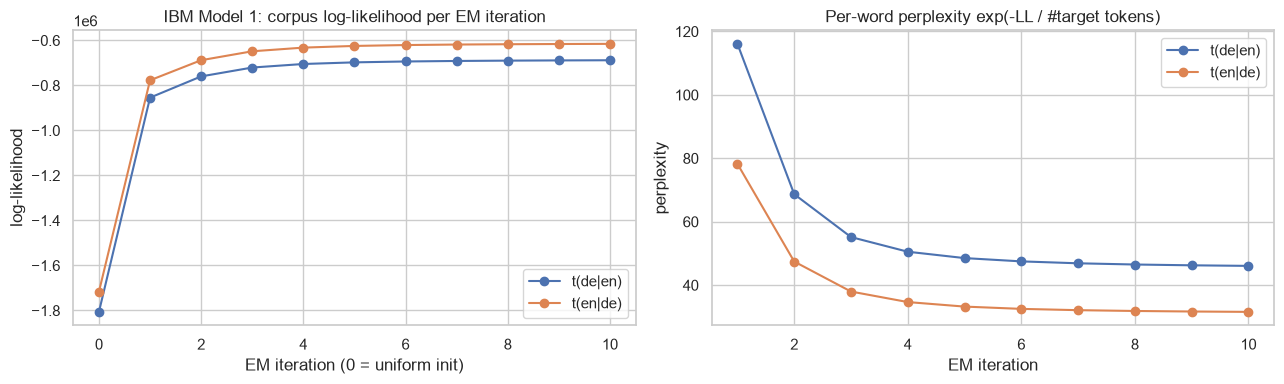

In [15]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
for name, h in hist.items():
    ax[0].plot(range(len(h)), h, marker='o', label=name)
    ax[1].plot(range(1, len(h)), np.exp(-np.array(h[1:]) / models[name].n_tokens), marker='o', label=name)
ax[0].set(title='IBM Model 1: corpus log-likelihood per EM iteration', xlabel='EM iteration (0 = uniform init)',
          ylabel='log-likelihood'); ax[0].legend()
ax[1].set(title='Per-word perplexity exp(-LL / #target tokens)', xlabel='EM iteration', ylabel='perplexity')
ax[1].legend()
plt.tight_layout(); plt.savefig(FIG / 'B_em_convergence.png', dpi=120); plt.show()

**Convergence.** The first iteration gives by far the largest gain, because it moves away from the uniform
initialization. After that the gains shrink quickly, and the last few iterations change the log-likelihood by
less than 0.2% each. EM converges to the global optimum here: Model 1's likelihood is concave in $t$, so the
uniform start is not a limitation. The $t(\text{en}\mid\text{de})$ direction has a lower per-word perplexity,
because German has the larger vocabulary (more conditioning words and a smaller English target vocabulary).

### B.3 Top-5 translation candidates for news-relevant words

In [16]:
NEWS_WORDS = ['government', 'bank', 'market', 'president', 'crisis', 'war', 'economy', 'election',
              'minister', 'said', 'police', 'court']
fmt = lambda pairs: [f'{w} ({p:.2f})' for w, p in pairs] + [''] * (5 - len(pairs))
top5_en = pd.DataFrame({w: fmt(m_de_en.top_translations(w)) for w in NEWS_WORDS},
                       index=[f'#{i}' for i in range(1, 6)]).T
top5_en.insert(0, 'train freq', [sum(s.count(w) for s in train_en) for w in NEWS_WORDS])
print('t(de | en): top-5 German translations of English news words')
top5_en

t(de | en): top-5 German translations of English news words


,train freq,#1,#2,#3,#4,#5
government,297,regierung (0.84),die (0.12),", (0.02)",der (0.01),. (0.01)
bank,105,bank (0.42),der (0.16),weltbank (0.13),die (0.09),zentralbank (0.09)
market,119,markt (0.27),des (0.22),die (0.13),dem (0.11),auf (0.09)
president,139,präsident (0.83),präsidenten (0.13),den (0.02),der (0.01),", (0.01)"
crisis,187,krise (0.83),der (0.07),finanzkrise (0.03),eine (0.03),die (0.03)
war,133,krieg (0.66),des (0.20),den (0.08),der (0.02),im (0.01)
economy,205,wirtschaft (0.60),volkswirtschaft (0.16),weltwirtschaft (0.15),die (0.04),der (0.02)
election,56,wahlen (0.38),wahl (0.30),im (0.11),den (0.11),bei (0.04)
minister,53,premierminister (0.24),dem (0.19),der (0.13),ministerpräsident (0.10),. (0.08)
said,37,: (0.14),", (0.12)",wird (0.12),ein (0.07),behaupten (0.07)


In [17]:
DE_WORDS = ['regierung', 'wirtschaft', 'krieg', 'wahlen', 'zentralbank', 'finanzkrise', 'sagte', 'nicht']
top5_de = pd.DataFrame({w: fmt(m_en_de.top_translations(w)) for w in DE_WORDS},
                       index=[f'#{i}' for i in range(1, 6)]).T
print('t(en | de): top-5 English translations of German words (the decoder direction)')
top5_de

t(en | de): top-5 English translations of German words (the decoder direction)


,#1,#2,#3,#4,#5
regierung,government (0.96),'s (0.02),the (0.01),to (0.00),. (0.00)
wirtschaft,economy (0.97),'s (0.02),the (0.01),", (0.00)",. (0.00)
krieg,war (1.00),the (0.00),one (0.00),. (0.00),of (0.00)
wahlen,elections (0.71),election (0.26),'s (0.02),its (0.00),the (0.00)
zentralbank,bank (0.51),central (0.49),the (0.00),from (0.00),european (0.00)
finanzkrise,financial (0.53),crisis (0.47),the (0.00),", (0.00)",it (0.00)
sagte,as (0.29),said (0.24),told (0.18),in (0.14),us (0.12)
nicht,not (0.92),. (0.03),", (0.02)",is (0.01),the (0.01)


**Reading the tables.** Frequent content words get sharp, correct distributions: *government → regierung*,
*president → präsident / präsidenten* (the inflected form ranks second), *crisis → krise*, *war → krieg*.
Three patterns repeat across the table:
1. **Inflection and compounding split the probability mass.** *economy* spreads over *wirtschaft*,
   *volkswirtschaft* and *weltwirtschaft*, and *bank* gives some of its mass to *weltbank* and *zentralbank*.
   One English word has to share its $t$ mass with every compound that contains it.
2. **Function words leak into content-word distributions** (*der, die, des, dem*). German articles carry
   case information that English does not have, and Model 1 has no other place to put them.
3. **Verbs of saying are poor.** *said* gets punctuation and *wird*. In this commentary corpus *said* is rare
   and appears in varied constructions (*sagte*, *erklärte*, *so …*), so Model 1 explains it with whatever
   co-occurs. This is the first sign of the domain mismatch between commentary and wire news.

### B.4 Alignment heatmaps
Each panel shows the **posterior** matrix $P(a_j = i \mid f, e)$ after EM. Red boxes mark the Viterbi
alignment $\hat a_j = \arg\max_i$. We show three training pairs: a German **compound**
(*wirtschaftswachstum* = *economic growth*), a **verb-final** subordinate clause
(*…, dass viele diese ansicht teilen werden*), and a news sentence whose participle *verschoben* moves to the
end of the clause. Both directions are shown: on the left German is generated from English, and on the right
English is generated from German (transposed, so the axes match).

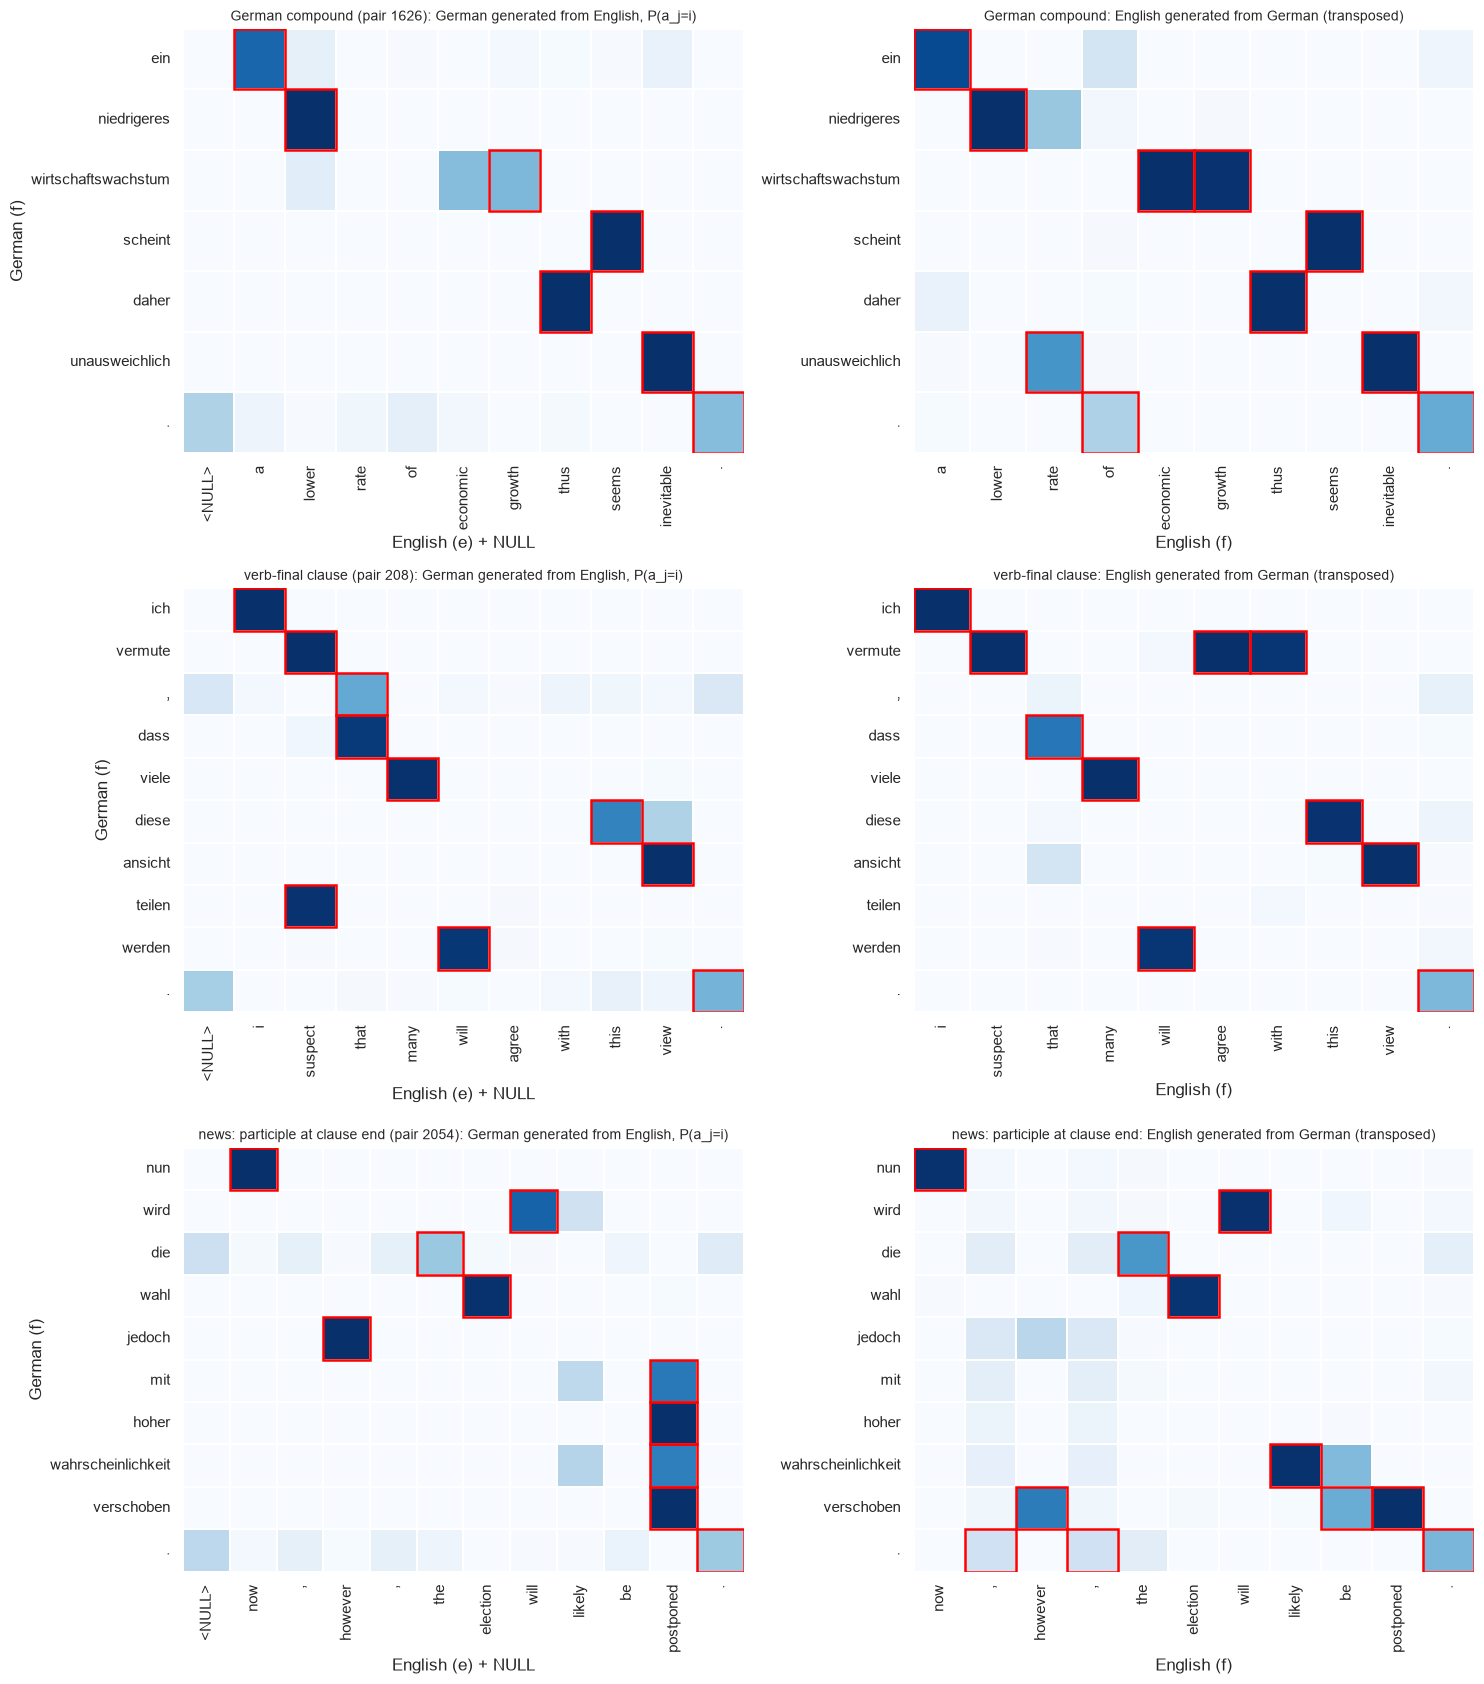

In [18]:
def find_pair(en_text, de_text):
    return next(k for k, (e, d) in enumerate(zip(train_en, train_de))
                if ' '.join(e) == en_text and ' '.join(d) == de_text)

HEATMAP_PAIRS = {
    'German compound': find_pair('a lower rate of economic growth thus seems inevitable .',
                                 'ein niedrigeres wirtschaftswachstum scheint daher unausweichlich .'),
    'verb-final clause': find_pair('i suspect that many will agree with this view .',
                                   'ich vermute , dass viele diese ansicht teilen werden .'),
    'news: participle at clause end': find_pair('now , however , the election will likely be postponed .',
                                                'nun wird die wahl jedoch mit hoher wahrscheinlichkeit verschoben .'),
}

def plot_alignment(ax, M, rows, cols, title, viterbi_axis=1):
    sns.heatmap(M, ax=ax, cmap='Blues', vmin=0, vmax=1, cbar=False, xticklabels=cols, yticklabels=rows,
                linewidths=.3, linecolor='white')
    best = M.argmax(viterbi_axis)
    for k, b in enumerate(best):
        r, c = (k, b) if viterbi_axis == 1 else (b, k)
        ax.add_patch(plt.Rectangle((c, r), 1, 1, fill=False, ec='red', lw=1.8))
    ax.set_title(title, fontsize=10); ax.tick_params(axis='x', rotation=90)

fig, axes = plt.subplots(3, 2, figsize=(15, 17))
for row, (label, s) in enumerate(HEATMAP_PAIRS.items()):
    en_s, de_s = train_en[s], train_de[s]
    plot_alignment(axes[row, 0], m_de_en.posteriors(s), de_s, [NULL] + en_s,
                   f'{label} (pair {s}): German generated from English, P(a_j=i)')
    axes[row, 0].set(ylabel='German (f)', xlabel='English (e) + NULL')
    M = m_en_de.posteriors(s).T                           # rows: DE (+NULL), cols: EN
    plot_alignment(axes[row, 1], M[1:], de_s, en_s,
                   f'{label}: English generated from German (transposed)', viterbi_axis=0)
    axes[row, 1].set(xlabel='English (f)')
plt.tight_layout(); plt.savefig(FIG / 'B_alignment_heatmaps.png', dpi=110); plt.show()

In [19]:
def viterbi_links(model, s, f_sent, e_sent):
    return [(f, e_sent[a - 1] if a else NULL) for f, a in zip(f_sent, model.viterbi(s))]

for label, s in HEATMAP_PAIRS.items():
    print(f'--- {label}')
    print('  de <- en :', viterbi_links(m_de_en, s, train_de[s], train_en[s]))
    print('  en <- de :', viterbi_links(m_en_de, s, train_en[s], train_de[s]))

--- German compound
  de <- en : [('ein', 'a'), ('niedrigeres', 'lower'), ('wirtschaftswachstum', 'growth'), ('scheint', 'seems'), ('daher', 'thus'), ('unausweichlich', 'inevitable'), ('.', '.')]
  en <- de : [('a', 'ein'), ('lower', 'niedrigeres'), ('rate', 'unausweichlich'), ('of', '<NULL>'), ('economic', 'wirtschaftswachstum'), ('growth', 'wirtschaftswachstum'), ('thus', 'daher'), ('seems', 'scheint'), ('inevitable', 'unausweichlich'), ('.', '.')]
--- verb-final clause
  de <- en : [('ich', 'i'), ('vermute', 'suspect'), (',', 'that'), ('dass', 'that'), ('viele', 'many'), ('diese', 'this'), ('ansicht', 'view'), ('teilen', 'suspect'), ('werden', 'will'), ('.', '.')]
  en <- de : [('i', 'ich'), ('suspect', 'vermute'), ('that', 'dass'), ('many', 'viele'), ('will', 'werden'), ('agree', 'vermute'), ('with', 'vermute'), ('this', 'diese'), ('view', 'ansicht'), ('.', '.')]
--- news: participle at clause end
  de <- en : [('nun', 'now'), ('wird', 'will'), ('die', 'the'), ('wahl', 'election'),

### B.5 Limitations of IBM Model 1, shown on our own output

In [20]:
# (1) No fertility: a German compound can be generated from only ONE English word.
s = HEATMAP_PAIRS['German compound']
post = m_de_en.posteriors(s)
j = train_de[s].index('wirtschaftswachstum')
print('P(a_j = i) for f = "wirtschaftswachstum":',
      {e: round(p, 3) for e, p in zip([NULL] + train_en[s], post[j]) if p > 0.01})
print('t(wirtschaftswachstum | economic) =', round(m_de_en.prob('wirtschaftswachstum', 'economic'), 4),
      '| t(wirtschaftswachstum | growth) =', round(m_de_en.prob('wirtschaftswachstum', 'growth'), 4))

# Corpus-wide: for pairs where English has "economic growth" and German has "wirtschaftswachstum",
# how often does the de<-en Viterbi alignment link the compound to "economic" vs "growth"?
links = Counter()
for k, (e, d) in enumerate(zip(train_en, train_de)):
    if 'wirtschaftswachstum' in d and 'economic growth' in ' '.join(e):
        a = m_de_en.viterbi(k)[d.index('wirtschaftswachstum')]
        links[e[a - 1] if a else NULL] += 1
print('compound "wirtschaftswachstum" Viterbi-linked to:', dict(links))

P(a_j = i) for f = "wirtschaftswachstum": {'lower': np.float64(0.112), 'economic': np.float64(0.433), 'growth': np.float64(0.456)}
t(wirtschaftswachstum | economic) = 0.0664 | t(wirtschaftswachstum | growth) = 0.0699
compound "wirtschaftswachstum" Viterbi-linked to: {'growth': 27, 'mobilization': 1, 'propels': 1, 'bathwater': 1}


In [21]:
# (2) No distortion: Model 1 ignores word positions. Shuffling the German sentence leaves P(f|e) unchanged
#     and simply permutes the rows of the posterior matrix -- the verb-final order is invisible to the model.
s = HEATMAP_PAIRS['verb-final clause']
en_s, de_s = train_en[s], train_de[s]
rng = random.Random(SEED)
shuffled = de_s[:]; rng.shuffle(shuffled)

def sent_loglik(model, fs, es):
    T = np.array([[model.prob(f, e) for e in [NULL] + es] for f in fs])
    return float(np.log(T.sum(1)).sum() - len(fs) * math.log(len(es) + 1))

print('original :', ' '.join(de_s), f'  log P(f|e) = {sent_loglik(m_de_en, de_s, en_s):.4f}')
print('shuffled :', ' '.join(shuffled), f'  log P(f|e) = {sent_loglik(m_de_en, shuffled, en_s):.4f}')

# Identical words get identical posteriors wherever they stand, so positional ties cannot be resolved.
k = next(k for k, (e, d) in enumerate(zip(train_en, train_de))
         if 8 <= len(d) <= 14 and d.count('die') >= 2 and e.count('the') >= 2)
P = m_de_en.posteriors(k); rows = [j for j, w in enumerate(train_de[k]) if w == 'die']
print(f'\npair {k}:', ' '.join(train_en[k]), '|||', ' '.join(train_de[k]))
print('"die" at German positions', rows, '-> Viterbi English positions',
      [int(m_de_en.viterbi(k)[j]) for j in rows], '(identical rows:',
      bool(np.allclose(P[rows[0]], P[rows[1]])), ')')

original : ich vermute , dass viele diese ansicht teilen werden .   log P(f|e) = -31.6711
shuffled : teilen dass , werden diese ansicht . viele ich vermute   log P(f|e) = -31.6711

pair 355: since then , however , the sd has fundamentally changed the country 's political landscape . ||| seitdem jedoch hat die sd die politische landschaft des landes grundlegend verändert .
"die" at German positions [3, 5] -> Viterbi English positions [6, 6] (identical rows: True )


In [22]:
# (3) NULL word and the garbage-collector effect of rare words.
freq_en = Counter(w for s in train_en for w in s)
fert = defaultdict(list)            # Viterbi fertility (#German words linked) per English token, by frequency band
null_words = Counter()
for k, (e, d) in enumerate(zip(train_en, train_de)):
    a = m_de_en.viterbi(k)
    n_linked = Counter(a)
    for i, w in enumerate(e, start=1):
        band = '1 (singleton)' if freq_en[w] == 1 else '2-5' if freq_en[w] <= 5 else '6-100' if freq_en[w] <= 100 else '>100'
        fert[band].append(n_linked[i])
    null_words.update(d[j] for j in range(len(d)) if a[j] == 0)
gc = pd.DataFrame({band: {'English tokens': len(v), 'mean Viterbi fertility': round(np.mean(v), 3),
                          'share with fertility >= 3 (%)': round(100 * np.mean(np.array(v) >= 3), 2)}
                   for band, v in sorted(fert.items())}).T
n_de_tokens = sum(map(len, train_de))
print(f'German tokens aligned to NULL: {sum(null_words.values()):,} / {n_de_tokens:,} '
      f'({100 * sum(null_words.values()) / n_de_tokens:.1f}%); most frequent: {null_words.most_common(10)}')
gc

German tokens aligned to NULL: 1,391 / 179,687 (0.8%); most frequent: [('die', 853), ('der', 243), (',', 229), ('.', 31), ('in', 21), ('das', 8), ('und', 3), ('zu', 1), ('sich', 1), ('ist', 1)]


,English tokens,mean Viterbi fertility,share with fertility >= 3 (%)
1 (singleton),7336.0,4.411,60.62
2-5,13558.0,1.893,25.07
6-100,56222.0,0.877,4.23
>100,101158.0,0.702,2.19


In [23]:
# A concrete garbage-collector example: the singleton English word that "collects" the most German words.
best = None
for k, (e, d) in enumerate(zip(train_en, train_de)):
    if len(e) > 15: continue
    a = m_de_en.viterbi(k); n_linked = Counter(a)
    for i, w in enumerate(e, start=1):
        if freq_en[w] == 1 and (best is None or n_linked[i] > best[0]):
            best = (n_linked[i], k, w)
n, k, w = best
print(f'pair {k}:\n  EN: {" ".join(train_en[k])}\n  DE: {" ".join(train_de[k])}')
print(f'singleton "{w}" is the Viterbi link of {n} German words:',
      [d for d, a in zip(train_de[k], m_de_en.viterbi(k)) if a and train_en[k][a - 1] == w])
print(f'top t(. | {w}):', [(f, round(p, 3)) for f, p in m_de_en.top_translations(w, 8)])

pair 9940:
  EN: the beatles used to sing that " money can 't buy love . "
  DE: die beatles sangen " money can ' t buy love " - für geld gibt ' s keine liebe zu kaufen .
singleton "beatles" is the Viterbi link of 13 German words: ['beatles', 'sangen', 'money', 'can', "'", 't', 'buy', 'love', '-', 'für', 'gibt', "'", 's']
top t(. | beatles): [("'", 0.151), ('love', 0.075), ('t', 0.075), ('can', 0.075), ('buy', 0.075), ('sangen', 0.075), ('beatles', 0.075), ('s', 0.075)]


**Discussion of limitations (with the evidence above).**
1. **No fertility (one-to-many).** Under the de←en model, each German word is generated by exactly one English
   word. The compound *wirtschaftswachstum* therefore links to *growth* **or** to *economic*, never to both, and
   the other English word looks untranslated. Across the corpus, the compound is linked to *growth* in 27 of 30
   pairs and never to both words. Its $t$ mass is split between the two English words, so neither
   explains the compound well. The same happens for *zentralbank* (*central bank*), *finanzkrise* (*financial
   crisis*) and *Bundesverfassungsgericht* (*Federal Constitutional Court*, three English words, and not even in
   our training data). This is the motivation for fertility in IBM Model 3, and here for phrase extraction on
   symmetrized alignments in Part C.
2. **No distortion (reordering).** The shuffled German sentence gets *exactly* the same likelihood as the
   original one. The model cannot tell that *teilen werden* is verb-final (the de←en Viterbi alignment even links
   *teilen* to *suspect* instead of *agree*), or that *verschoben* belongs at the
   end of the clause. Two copies of *die* get identical posterior rows, so their Viterbi links are the same no
   matter where they stand. Alignment comes from lexical co-occurrence only, so frequent words such as
   *die/der*, commas and auxiliaries align almost at random between their candidates. IBM Model 2 (absolute
   distortion) and the HMM alignment model (relative jumps) address this.
3. **NULL word and the garbage-collector effect.** NULL is rarely the Viterbi choice: only 0.8% of German tokens
   are aligned to it, almost all of them articles (*die, der*) and punctuation. NULL competes with every real
   English word in the sentence and loses to any word that co-occurs often, so German articles are usually
   forced onto some English noun or onto *the*, even when English has no article. In the other direction, rare
   English words act as **garbage collectors**: a singleton has only one sentence to explain. EM can raise its
   $t$ for several co-occurring German words at once without hurting any other sentence, so singletons have a
   much higher mean Viterbi fertility than frequent words (table above), and the concrete example shows a
   singleton absorbing several unrelated German words. With 60% singleton German types (Part A), this noise
   goes straight into the phrase table.
4. **Asymmetry.** The two directions produce different alignments (see the right-hand heatmaps). Neither is a
   valid many-to-many alignment, which is why Part C symmetrizes them.

## Part C — Phrase-based SMT

### C.1 Viterbi alignments and symmetrization
For every training pair we take the Viterbi alignment of each direction and combine them (Och & Ney 2003):
* **intersection**: links found by both directions. High precision, but very sparse.
* **union**: links found by either direction. High recall, but noisy, and it blocks many phrase pairs.
* **grow-diag-final** (Koehn et al. 2003): start from the intersection, add neighbouring union links
  (including diagonal neighbours) that connect a still-unaligned word, then add any remaining union link whose
  English and German words are both unaligned.

In [24]:
NEIGHBOURS = [(-1, 0), (0, -1), (1, 0), (0, 1), (-1, -1), (-1, 1), (1, -1), (1, 1)]

def directional_links(s):
    """Viterbi links of both directions as sets of (en_pos, de_pos), 0-based, NULL links dropped."""
    a_de = m_de_en.viterbi(s)       # for every German position j: aligned English position (1-based, 0 = NULL)
    a_en = m_en_de.viterbi(s)       # for every English position i: aligned German position
    de_en = {(int(i) - 1, j) for j, i in enumerate(a_de) if i > 0}
    en_de = {(i, int(j) - 1) for i, j in enumerate(a_en) if j > 0}
    return de_en, en_de

def symmetrize(A1, A2, n_en, n_de, method='grow-diag-final'):
    inter, union = A1 & A2, A1 | A2
    if method == 'intersection': return inter
    if method == 'union': return union
    A = set(inter)
    en_al, de_al = Counter(i for i, _ in A), Counter(j for _, j in A)
    def add(i, j):
        A.add((i, j)); en_al[i] += 1; de_al[j] += 1
    grown = True
    while grown:                                   # grow-diag
        grown = False
        for i, j in sorted(A):
            for di, dj in NEIGHBOURS:
                ni, nj = i + di, j + dj
                if (0 <= ni < n_en and 0 <= nj < n_de and (ni, nj) in union and (ni, nj) not in A
                        and (en_al[ni] == 0 or de_al[nj] == 0)):
                    add(ni, nj); grown = True
    if method == 'grow-diag': return A
    for i, j in sorted(union):                     # final-and
        if en_al[i] == 0 and de_al[j] == 0:
            add(i, j)
    return A

SYM_METHODS = ['intersection', 'grow-diag-final', 'union']
alignments = {m: [] for m in SYM_METHODS}
for s, (e, d) in enumerate(zip(train_en, train_de)):
    A1, A2 = directional_links(s)
    for m in SYM_METHODS:
        alignments[m].append(symmetrize(A1, A2, len(e), len(d), m))

n_en_tok, n_de_tok = sum(map(len, train_en)), sum(map(len, train_de))
sym_stats = pd.DataFrame({m: {
    'alignment points': sum(map(len, A)),
    'points / sentence': round(np.mean(list(map(len, A))), 2),
    'unaligned EN tokens (%)': round(100 * (1 - sum(len({i for i, _ in a}) for a in A) / n_en_tok), 1),
    'unaligned DE tokens (%)': round(100 * (1 - sum(len({j for _, j in a}) for a in A) / n_de_tok), 1),
} for m, A in alignments.items()}).T
sym_stats

,alignment points,points / sentence,unaligned EN tokens (%),unaligned DE tokens (%)
intersection,90310.0,9.03,49.3,49.7
grow-diag-final,159255.0,15.93,22.6,23.6
union,265022.0,26.50,0.7,0.8


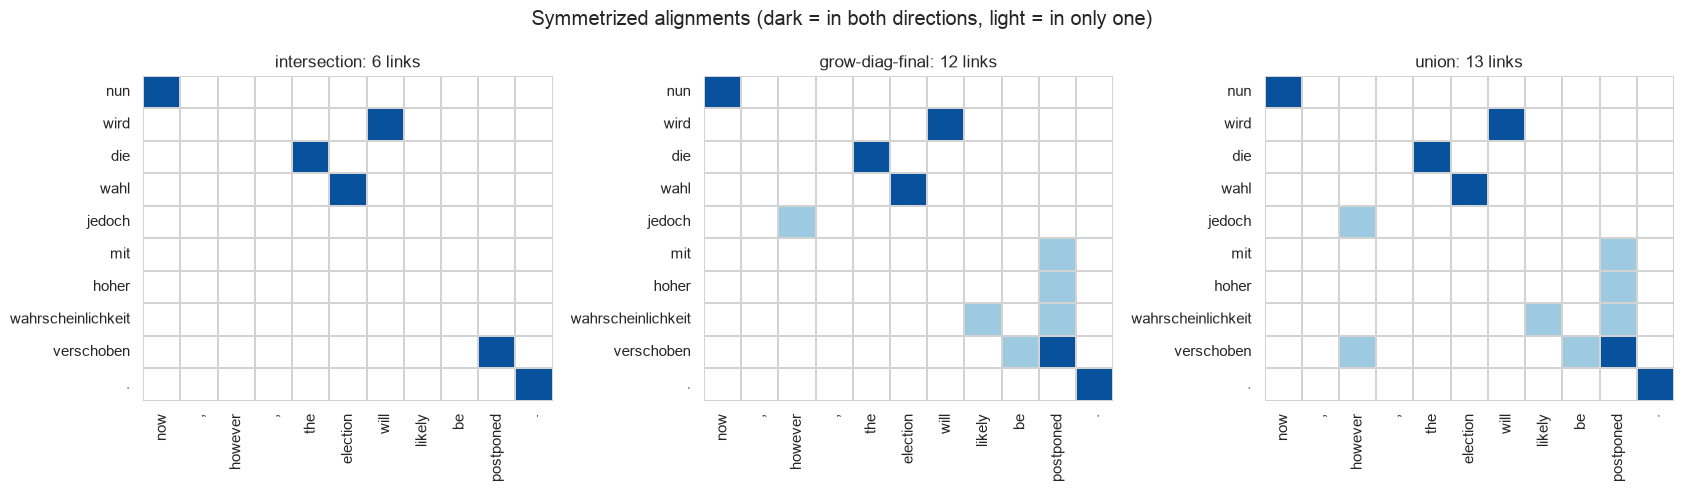

In [25]:
s = HEATMAP_PAIRS['news: participle at clause end']
e, d = train_en[s], train_de[s]
A1, A2 = directional_links(s)
fig, axes = plt.subplots(1, 3, figsize=(17, 5))
for ax, m in zip(axes, SYM_METHODS):
    M = np.zeros((len(d), len(e)))
    for i, j in alignments[m][s]:
        M[j, i] = 1 + ((i, j) in A1 and (i, j) in A2)       # 2 = both directions agree
    sns.heatmap(M, ax=ax, cmap=sns.color_palette(['white', '#9ecae1', '#08519c'], as_cmap=True), vmin=0, vmax=2,
                cbar=False, xticklabels=e, yticklabels=d, linewidths=.3, linecolor='lightgray')
    ax.set_title(f'{m}: {len(alignments[m][s])} links'); ax.tick_params(axis='x', rotation=90)
fig.suptitle('Symmetrized alignments (dark = in both directions, light = in only one)')
plt.tight_layout(); plt.savefig(FIG / 'C_symmetrization.png', dpi=110); plt.show()

**Choice: grow-diag-final.** The intersection leaves about half of the tokens unaligned, and phrase
extraction then attaches them freely to neighbouring phrases, which produces many loose and over-long phrase
pairs. The union is dense but contains the Model 1 noise from both directions (garbage-collector links, random
article links), and its inconsistent links rule out many correct phrase pairs. Grow-diag-final keeps the
reliable intersection as its backbone and adds union links only next to existing links or for still-unaligned
words. It is the standard Moses default and the best trade-off in Koehn et al. (2003). The extraction counts
below make the trade-off visible.

### C.2 Phrase extraction (Koehn, Och & Marcu 2003)
A phrase pair $(\bar e_{i_1..i_2}, \bar d_{j_1..j_2})$ is **consistent** with alignment $A$ if it contains at
least one link and no word inside the pair is linked to a word outside it. We enumerate English spans of up to
`MAX_PHRASE_LEN` = 4 words, take the minimal German span covering their links, reject the pair if a German word
in that span links outside the English span, and then extend the German side over neighbouring **unaligned**
words (still ≤ 4 words).

In [26]:
def extract_phrases(e, d, A, max_len=C['MAX_PHRASE_LEN']):
    """All phrase pairs (en_phrase, de_phrase) consistent with alignment A (set of (en_pos, de_pos))."""
    de_aligned = Counter(j for _, j in A)
    pairs = []
    for i1 in range(len(e)):
        for i2 in range(i1, min(len(e), i1 + max_len)):
            js = [j for i, j in A if i1 <= i <= i2]
            if not js:
                continue
            j1, j2 = min(js), max(js)
            if j2 - j1 >= max_len:
                continue
            if any(j1 <= j <= j2 and not i1 <= i <= i2 for i, j in A):     # consistency check
                continue
            src = ' '.join(e[i1:i2 + 1])
            js_ = j1
            while js_ >= 0 and (js_ == j1 or de_aligned[js_] == 0):         # extend over unaligned DE words
                je_ = j2
                while je_ < len(d) and (je_ == j2 or de_aligned[je_] == 0) and je_ - js_ < max_len:
                    pairs.append((src, ' '.join(d[js_:je_ + 1])))
                    je_ += 1
                js_ -= 1
    return pairs

phrase_counts, extraction_stats = {}, {}
for m in SYM_METHODS:
    t0 = time.perf_counter()
    cnt = Counter()
    for e, d, A in zip(train_en, train_de, alignments[m]):
        cnt.update(extract_phrases(e, d, A))
    phrase_counts[m] = cnt
    extraction_stats[m] = {'phrase pair tokens': sum(cnt.values()), 'unique phrase pairs': len(cnt),
                           'unique EN phrases': len({p for p, _ in cnt}), 'seconds': round(time.perf_counter() - t0, 1)}
pd.DataFrame(extraction_stats).T

,phrase pair tokens,unique phrase pairs,unique EN phrases,seconds
intersection,1244534.0,1090147.0,240090.0,1.2
grow-diag-final,529053.0,412345.0,143044.0,1.1
union,82855.0,22112.0,18753.0,1.0


In [27]:
pairs = phrase_counts[SMT['SYMMETRIZATION']]
print(f'Using {SMT["SYMMETRIZATION"]}: extracted {sum(pairs.values()):,} phrase-pair tokens, '
      f'{len(pairs):,} unique phrase pairs (max length {C["MAX_PHRASE_LEN"]}).')
len_dist = pd.crosstab(pd.Series([len(p.split()) for p, _ in pairs], name='EN length'),
                       pd.Series([len(q.split()) for _, q in pairs], name='DE length'))
len_dist

Using grow-diag-final: extracted 529,053 phrase-pair tokens, 412,345 unique phrase pairs (max length 4).


DE length,1,2,3,4
EN length,,,,
1,14579,35084,22062,11105
2,33148,50252,33506,18139
3,21213,33032,37720,24172
4,10851,17576,24177,25729


### C.3 Phrase translation table
With $f$ the English source phrase and $e$ the German target phrase (noisy-channel notation):

* $\phi(f \mid e) = \dfrac{\text{count}(e, f)}{\text{count}(e)}$, the **noisy-channel translation model**
  $P(\text{en} \mid \text{de})$ from the assignment formula.
* $\phi(e \mid f) = \dfrac{\text{count}(e, f)}{\text{count}(f)}$, the **inverse (direct) model**, added as a second
  feature, as in Moses.

The table is indexed by English phrase, because the decoder looks up translation options for source spans. It is
**pruned to the top `TABLE_LIMIT` = 20 German options** per English phrase, ranked by the direct probability
$\phi(e\mid f)$. We do not rank by $\phi(f\mid e)$, because a German phrase seen only once gets
$\phi(f\mid e) = 1$ (e.g. *the government → der regierungsverhältnisse*), and such noisy singletons would push
out the frequent, correct options.

In [28]:
def build_phrase_table(pair_counts, table_limit=SMT['TABLE_LIMIT']):
    cnt_f, cnt_e = Counter(), Counter()                  # f = English phrase, e = German phrase
    for (f, e), c in pair_counts.items():
        cnt_f[f] += c; cnt_e[e] += c
    table = defaultdict(list)
    for (f, e), c in pair_counts.items():
        table[f].append((tuple(e.split()), math.log(c / cnt_e[e]), math.log(c / cnt_f[f]), c))
    for f in table:
        table[f].sort(key=lambda o: -o[2])                 # rank by phi(e|f): robust to rare German phrases
        del table[f][table_limit:]
    return dict(table)

phrase_table = build_phrase_table(pairs)
print(f'phrase table: {len(phrase_table):,} English phrases, '
      f'{sum(map(len, phrase_table.values())):,} entries after top-{SMT["TABLE_LIMIT"]} pruning')

def show_options(f, k=5):
    return pd.DataFrame([(f, ' '.join(e), round(math.exp(a), 3), round(math.exp(b), 3), c)
                         for e, a, b, c in phrase_table.get(f, [])[:k]],
                        columns=['EN phrase f', 'DE phrase e', 'phi(f|e)', 'phi(e|f)', 'count'])

pd.concat([show_options(f, 4) for f in ['the government', 'central bank', 'economic growth',
                                         'the financial crisis', 'said that', 'will be']], ignore_index=True)

phrase table: 143,044 English phrases, 361,832 entries after top-20 pruning


,EN phrase f,DE phrase e,phi(f|e),phi(e|f),count
0,the government,die regierung,0.319,0.345,30
1,the government,regierung,0.035,0.126,11
2,the government,der regierung,0.085,0.046,4
3,the government,", die regierung",0.500,0.023,2
4,central bank,zentralbank,0.568,0.525,21
5,central bank,der zentralbanken,0.222,0.050,2
6,central bank,zentralbanken,0.069,0.050,2
7,central bank,notenbanken,0.167,0.025,1
8,economic growth,wirtschaftswachstum,0.525,0.309,21
9,economic growth,das wirtschaftswachstum,0.417,0.074,5


### C.4 German trigram language model (interpolated Kneser–Ney, own implementation)
We implement **interpolated Kneser–Ney** (Kneser & Ney 1995; Chen & Goodman 1999) with one absolute discount
$D = 0.75$:

$$P_{KN}(w \mid u v) = \frac{\max(c(uvw) - D, 0)}{c(uv\cdot)} + \frac{D\,N_{1+}(uv\cdot)}{c(uv\cdot)}\,P_{KN}(w \mid v)$$

Lower orders use **continuation counts** $N_{1+}(\cdot\, v w)$ instead of raw counts. The recursion ends in a
uniform distribution over the vocabulary plus `<unk>`. Unseen contexts fall back to the next lower order.

*Why not `nltk.lm.KneserNeyInterpolated`?* It gives the same estimates in principle, but it recomputes each
probability recursively without caching. The decoder makes millions of LM queries, so NLTK would make the beam
sweep take hours. Our version stores the count tables in dictionaries and memoises queries. As a sanity check,
we verify that the probabilities for a given context sum to 1.

In [29]:
class KneserNeyLM:
    BOS, EOS, UNK = '<s>', '</s>', '<unk>'

    def __init__(self, sents, order=C['LM_ORDER'], discount=SMT['KN_DISCOUNT']):
        self.n, self.D = order, discount
        self.vocab = {w for s in sents for w in s} | {self.EOS, self.UNK}
        self.counts = [Counter() for _ in range(order + 1)]       # counts[m][ngram]
        for s in sents:
            toks = [self.BOS] * (order - 1) + s + [self.EOS]
            for k in range(order - 1, len(toks)):
                self.counts[order][tuple(toks[k - order + 1:k + 1])] += 1
        for m in range(order - 1, 0, -1):                          # continuation counts N1+(. w_2..w_m)
            for g in self.counts[m + 1]:
                self.counts[m][g[1:]] += 1
        self.ctx_total = [Counter() for _ in range(order + 1)]
        self.ctx_types = [Counter() for _ in range(order + 1)]
        for m in range(1, order + 1):
            for g, c in self.counts[m].items():
                self.ctx_total[m][g[:-1]] += c
                self.ctx_types[m][g[:-1]] += 1
        self._cache = {}

    def prob(self, w, ctx):
        """P(w | ctx) where ctx is a tuple of the (n-1) previous tokens."""
        key = (w, ctx)
        p = self._cache.get(key)
        if p is not None:
            return p
        w_ = w if w in self.vocab else self.UNK
        p = 1.0 / len(self.vocab)
        for m in range(1, self.n + 1):
            h = tuple(ctx[len(ctx) - m + 1:]) if m > 1 else ()
            if len(h) != m - 1:
                break
            tot = self.ctx_total[m].get(h, 0)
            if tot == 0:
                break                                           # unseen context: keep the lower-order estimate
            p = max(self.counts[m].get(h + (w_,), 0) - self.D, 0) / tot + self.D * self.ctx_types[m][h] / tot * p
        self._cache[key] = p
        return p

    def logprob(self, w, ctx):
        return math.log(self.prob(w, ctx))

    def sentence_logprob(self, s):
        ctx, lp = (self.BOS,) * (self.n - 1), 0.0
        for w in s + [self.EOS]:
            lp += self.logprob(w, ctx); ctx = ctx[1:] + (w,)
        return lp

    def perplexity(self, sents):
        return math.exp(-sum(self.sentence_logprob(s) for s in sents) / sum(len(s) + 1 for s in sents))

class AddKTrigramLM(KneserNeyLM):
    """Baseline for comparison: add-k smoothed trigram (no interpolation)."""
    def __init__(self, sents, k=0.01):
        super().__init__(sents, order=3); self.k = k
        self.raw2 = Counter()
        for g, c in self.counts[3].items():
            self.raw2[g[:2]] += c
    def prob(self, w, ctx):
        w_ = w if w in self.vocab else self.UNK
        return (self.counts[3].get(tuple(ctx[-2:]) + (w_,), 0) + self.k) / (self.raw2.get(tuple(ctx[-2:]), 0) + self.k * len(self.vocab))

t0 = time.perf_counter()
lm = KneserNeyLM(train_de)
print(f'KN trigram LM trained on {len(train_de):,} German sentences in {time.perf_counter() - t0:.1f}s; '
      f'|V| = {len(lm.vocab):,}; {len(lm.counts[3]):,} trigram types')
for ctx in [('die', 'regierung'), ('<s>', '<s>'), ('nie', 'gesehen')]:
    print(f'  sum_w P(w | {ctx}) = {sum(lm.prob(w, ctx) for w in lm.vocab):.6f}')

oov_rate = 100 * np.mean([w not in lm.vocab for s in lm_heldout for w in s])
lm_table = pd.DataFrame({
    'held-out perplexity (lm_heldout.tok.de)': {
        'KN trigram (ours)': lm.perplexity(lm_heldout),
        'KN bigram (ours)': KneserNeyLM(train_de, order=2).perplexity(lm_heldout),
        'add-0.01 trigram': AddKTrigramLM(train_de, 0.01).perplexity(lm_heldout),
        'add-1 trigram': AddKTrigramLM(train_de, 1.0).perplexity(lm_heldout)},
    'training perplexity (first 500 train sents)': {
        'KN trigram (ours)': lm.perplexity(train_de[:500]), 'KN bigram (ours)': np.nan,
        'add-0.01 trigram': np.nan, 'add-1 trigram': np.nan}}).round(1)
print(f'held-out OOV token rate: {oov_rate:.2f}% (mapped to <unk>)')
lm_table

KN trigram LM trained on 10,000 German sentences in 0.2s; |V| = 23,199; 157,831 trigram types
  sum_w P(w | ('die', 'regierung')) = 1.000000
  sum_w P(w | ('<s>', '<s>')) = 1.000000
  sum_w P(w | ('nie', 'gesehen')) = 1.000000


held-out OOV token rate: 7.26% (mapped to <unk>)


,held-out perplexity (lm_heldout.tok.de),training perplexity (first 500 train sents)
KN trigram (ours),481.9,8.6
KN bigram (ours),493.2,NaN
add-0.01 trigram,7429.5,NaN
add-1 trigram,14563.6,NaN


**LM results.** The interpolated KN trigram reaches a held-out perplexity of about **480** on
`lm_heldout.tok.de`, which is in the expected range for a 180k-token training corpus with ~7.5% OOV tokens. It
beats the KN bigram (the trigram context helps even with this little data) and is far better than add-k
smoothing: add-1 gives a huge share of the probability mass to the ~23k × 23k unseen continuations. The large gap
between training perplexity (≈9) and held-out perplexity shows how sparse German trigrams are at this corpus
size. This weak LM is one of the main limits on SMT fluency below.

### C.5 Decoder (own implementation): stack decoding with beam search
We use a phrase-based **stack decoder** in the style of Koehn (2004) and Collins' notes. A hypothesis is
(coverage bit-vector of the English words already translated, last two German words, end of the last
translated source span, score). Stack $k$ holds hypotheses that cover $k$ source words.

**Score** (log-linear, an extension of the assignment's two-feature formula, with e = German, f = English):

$$\text{score}(e) = \lambda_1 \log \phi(f\mid e) + \lambda_{inv} \log \phi(e\mid f) + \lambda_2 \log P_{LM}(e)
                  + \lambda_{wp}\,|e| - \lambda_{d} \sum |\text{start}_k - \text{end}_{k-1}|$$

* **Translation options** for every span of up to 4 English words come from the phrase table.
  An **unknown source word** has no option, so it is **passed through unchanged** with a fixed penalty
  (`OOV_PENALTY`). This matters for names and numbers, and for the OOV analysis in Part D.
* **Reordering**: limited jumps (distortion limit 4) with a linear distortion penalty. Hypotheses that can no
  longer reach the leftmost untranslated word are not created, so the search never hits a dead end.
* **Future-cost estimate** for the uncovered spans (best TM + in-phrase LM score per span, combined by dynamic
  programming), so hypotheses that translated easy and hard parts are ranked fairly within a stack.
* **Recombination**: hypotheses with the same coverage, LM state and last position are merged, keeping the best.
* **Beam (histogram pruning)**: only the `beam` best hypotheses of each stack (by score + future cost) are
  expanded. `beam = 1` is a greedy decoder.

In [30]:
class StackDecoder:
    def __init__(self, phrase_table, lm, weights, max_phrase_len=C['MAX_PHRASE_LEN'],
                 distortion_limit=SMT['DISTORTION_LIMIT'], oov_penalty=SMT['OOV_PENALTY']):
        self.pt, self.lm, self.w = phrase_table, lm, weights
        self.L, self.dl, self.oov_penalty = max_phrase_len, distortion_limit, oov_penalty

    def _options(self, src):
        """(i, j) -> list of (german tuple, weighted TM + word-penalty score)."""
        w, opts, n = self.w, {}, len(src)
        for i in range(n):
            for j in range(i + 1, min(n, i + self.L) + 1):
                entry = self.pt.get(' '.join(src[i:j]))
                if entry:
                    opts[(i, j)] = [(e, w['tm'] * a + w['tm_inv'] * b + w['wp'] * len(e)) for e, a, b, _ in entry]
            if (i, i + 1) not in opts:                          # unknown word -> pass through unchanged
                opts[(i, i + 1)] = [((src[i],), self.oov_penalty + w['wp'])]
        return opts

    def _future_costs(self, opts, n):
        fc = np.full((n + 1, n + 1), -np.inf)
        for (i, j), ol in opts.items():
            for e, s in ol:
                lm_est, ctx = 0.0, ()
                for word in e:
                    lm_est += self.lm.logprob(word, ctx); ctx = (ctx + (word,))[-2:]
                fc[i, j] = max(fc[i, j], s + self.w['lm'] * lm_est)
        for length in range(2, n + 1):
            for i in range(n - length + 1):
                j = i + length
                for k in range(i + 1, j):
                    fc[i, j] = max(fc[i, j], fc[i, k] + fc[k, j])
        return fc

    def translate(self, src, beam=5):
        n = len(src)
        if n == 0:
            return []
        opts = self._options(src)
        fc = self._future_costs(opts, n)
        spans = sorted(opts)
        full = (1 << n) - 1

        def future(cov):
            total, i = 0.0, 0
            while i < n:
                if cov >> i & 1:
                    i += 1; continue
                j = i
                while j < n and not cov >> j & 1:
                    j += 1
                total += fc[i, j]; i = j
            return total

        def first_gap(cov):
            return (~cov & (cov + 1)).bit_length() - 1

        # stacks[k]: (coverage, lm_state, last_end) -> (score, score + future, output words)
        stacks = [dict() for _ in range(n + 1)]
        stacks[0][(0, (KneserNeyLM.BOS,) * 2, 0)] = (0.0, future(0), ())
        w_lm, w_d = self.w['lm'], self.w['dist']
        for k in range(n):
            if not stacks[k]:
                continue
            survivors = sorted(stacks[k].items(), key=lambda kv: -kv[1][1])[:beam]
            for (cov, ctx, last), (score, _, words) in survivors:
                gap = first_gap(cov)
                for (i, j) in spans:
                    if i - gap > self.dl or abs(i - last) > self.dl:
                        continue
                    mask = ((1 << j) - 1) ^ ((1 << i) - 1)
                    if cov & mask:
                        continue
                    ncov = cov | mask
                    if ncov != full:
                        ngap = first_gap(ncov)
                        if ngap < i and j - ngap > self.dl:       # leftmost gap would become unreachable
                            continue
                    nk = k + (j - i)
                    base = score - w_d * abs(i - last)
                    fut = future(ncov)
                    for e, s in opts[(i, j)]:
                        lm_s, c = 0.0, ctx
                        for word in e:
                            lm_s += self.lm.logprob(word, c); c = (c[1], word)
                        if ncov == full:
                            lm_s += self.lm.logprob(KneserNeyLM.EOS, c)
                        ns = base + s + w_lm * lm_s
                        key = (ncov, c, j)
                        old = stacks[nk].get(key)
                        if old is None or old[0] < ns:             # recombination
                            stacks[nk][key] = (ns, ns + fut, words + e)
        if not stacks[n]:                                       # safety net (not expected to trigger)
            return [w for i in range(n) for w in opts[(i, i + 1)][0][0]]
        return list(max(stacks[n].values(), key=lambda h: h[0])[2])

def detok(tokens):
    return DETOK.detokenize(tokens)

def sacre_bleu(hyps_detok, refs_raw):
    """Case-insensitive sacreBLEU (13a) on detokenized text -- the same metric as Part D."""
    return sacrebleu.corpus_bleu(hyps_detok, [refs_raw], lowercase=True).score

### C.6 Weight tuning on a development slice (not the test set)
To keep the test set clean, we hold out the **last 300 training pairs** as a development set. We rebuild the
whole pipeline (IBM Model 1 in both directions, grow-diag-final, extraction, phrase table, KN LM) on the
remaining 9,700 pairs and grid-search the LM weight, the word penalty and the distortion weight at beam 5
($\lambda_{tm} = \lambda_{inv} = 1$ fixed). The best weights are then used with the full 10k-pair model.
This is a small stand-in for MERT (Och 2003).

In [31]:
def build_pipeline(en_sents, de_sents, iters=C['EM_ITERS'], sym=SMT['SYMMETRIZATION']):
    """Parts B + C end to end: IBM1 x 2 -> Viterbi -> symmetrize -> extract -> phrase table, plus KN LM."""
    mde, men = IBMModel1(de_sents, en_sents), IBMModel1(en_sents, de_sents)
    mde.train(iters); men.train(iters)
    cnt = Counter()
    for s, (e, d) in enumerate(zip(en_sents, de_sents)):
        a_de, a_en = mde.viterbi(s), men.viterbi(s)
        A1 = {(int(i) - 1, j) for j, i in enumerate(a_de) if i > 0}
        A2 = {(i, int(j) - 1) for i, j in enumerate(a_en) if j > 0}
        cnt.update(extract_phrases(e, d, symmetrize(A1, A2, len(e), len(d), sym)))
    return build_phrase_table(cnt), KneserNeyLM(de_sents)

n_dev = SMT['N_DEV']
t0 = time.perf_counter()
dev_pt, dev_lm = build_pipeline(train_en[:-n_dev], train_de[:-n_dev])
dev_src, dev_ref = train_en[-n_dev:], train_de[-n_dev:]
print(f'tuning pipeline rebuilt on {len(train_en) - n_dev:,} pairs in {time.perf_counter() - t0:.1f}s')

grid = []
t0 = time.perf_counter()
for lam_lm in [0.5, 1.0, 1.5]:
    for wp in [-0.5, 0.0, 0.5, 1.0]:
        for dist in [0.25, 0.5]:
            W = dict(tm=1.0, tm_inv=1.0, lm=lam_lm, wp=wp, dist=dist)
            dec = StackDecoder(dev_pt, dev_lm, W)
            hyps = [dec.translate(s, beam=5) for s in dev_src]
            grid.append({**W, 'dev BLEU': sacrebleu.corpus_bleu([' '.join(h) for h in hyps],
                                                                 [[' '.join(r) for r in dev_ref]], tokenize='none').score,
                         'len ratio': sum(map(len, hyps)) / sum(map(len, dev_ref))})
grid = pd.DataFrame(grid).sort_values('dev BLEU', ascending=False).reset_index(drop=True)
WEIGHTS = grid.iloc[0][['tm', 'tm_inv', 'lm', 'wp', 'dist']].astype(float).to_dict()
print(f'{len(grid)} weight settings decoded in {time.perf_counter() - t0:.0f}s; chosen weights: {WEIGHTS}')
del dev_pt, dev_lm
grid.head(8).round(3)

tuning pipeline rebuilt on 9,700 pairs in 5.5s


24 weight settings decoded in 41s; chosen weights: {'tm': 1.0, 'tm_inv': 1.0, 'lm': 0.5, 'wp': 0.5, 'dist': 0.5}


,tm,tm_inv,lm,wp,dist,dev BLEU,len ratio
0,1.0,1.0,0.5,0.5,0.50,10.078,1.013
1,1.0,1.0,0.5,0.0,0.50,9.940,0.953
2,1.0,1.0,0.5,0.0,0.25,9.888,0.956
3,1.0,1.0,0.5,0.5,0.25,9.845,1.017
4,1.0,1.0,0.5,-0.5,0.50,9.673,0.912
5,1.0,1.0,1.0,1.0,0.50,9.665,0.944
6,1.0,1.0,1.0,1.0,0.25,9.483,0.948
7,1.0,1.0,0.5,-0.5,0.25,9.432,0.911


### C.7 Beam-width sweep on the 500-sentence test set
Every test sentence is decoded once per beam width, and each sentence is timed separately
(`time.perf_counter`, single thread, LM cache cleared before each run so all widths start cold). BLEU is
case-insensitive sacreBLEU on detokenized output against `test.raw.de`, the same metric as Part D.

In [32]:
decoder = StackDecoder(phrase_table, lm, WEIGHTS)
sweep, sweep_out, sweep_times = [], {}, {}
for beam in C['BEAMS']:
    lm._cache.clear()
    outs, secs = [], []
    for s in test_en:
        t0 = time.perf_counter()
        outs.append(decoder.translate(s, beam=beam))
        secs.append(time.perf_counter() - t0)
    sweep_out[beam], sweep_times[beam] = outs, secs
    sweep.append({'beam': beam,
                  'BLEU (sacreBLEU, lowercased, detok)': sacre_bleu([detok(h) for h in outs], test_raw_de),
                  'BLEU (tokenized, tokenize=none)': sacrebleu.corpus_bleu(
                      [' '.join(h) for h in outs], [[' '.join(r) for r in test_de]], tokenize='none').score,
                  'ms / sentence (mean)': 1000 * np.mean(secs), 'ms / sentence (p95)': 1000 * np.percentile(secs, 95),
                  'total s': sum(secs), 'hyp/ref length': sum(map(len, outs)) / sum(map(len, test_de))})
sweep = pd.DataFrame(sweep).set_index('beam')
sweep.round(2)

,"BLEU (sacreBLEU, lowercased, detok)","BLEU (tokenized, tokenize=none)",ms / sentence (mean),ms / sentence (p95),total s,hyp/ref length
beam,,,,,,
1,8.00,8.24,3.51,5.87,1.76,1.02
2,8.66,8.85,4.89,8.36,2.45,1.02
5,8.82,9.04,9.62,16.00,4.81,1.01
10,8.75,9.00,15.61,26.36,7.80,1.02


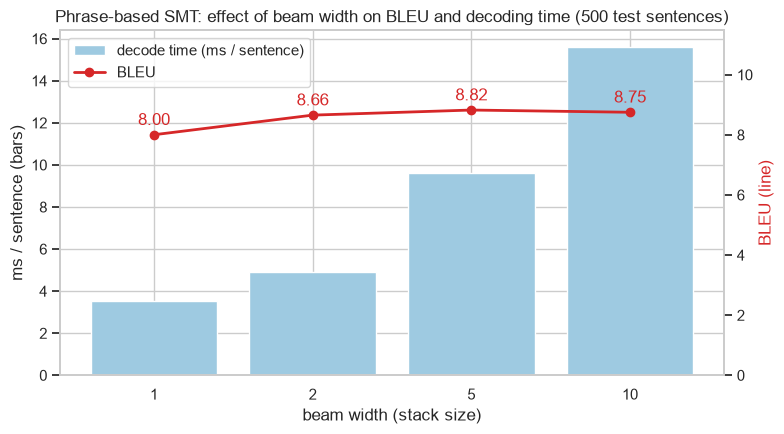

In [33]:
fig, ax1 = plt.subplots(figsize=(8, 4.5))
b = sweep.index.astype(str)
ax1.bar(b, sweep['ms / sentence (mean)'], color='#9ecae1', label='decode time (ms / sentence)')
ax1.set(xlabel='beam width (stack size)', ylabel='ms / sentence (bars)')
ax2 = ax1.twinx()
ax2.plot(b, sweep['BLEU (sacreBLEU, lowercased, detok)'], color='#d62728', marker='o', lw=2, label='BLEU')
for x, y in zip(b, sweep['BLEU (sacreBLEU, lowercased, detok)']):
    ax2.annotate(f'{y:.2f}', (x, y), textcoords='offset points', xytext=(0, 7), ha='center', color='#d62728')
ax2.set_ylabel('BLEU (line)', color='#d62728'); ax2.grid(False)
ax2.set_ylim(0, sweep['BLEU (sacreBLEU, lowercased, detok)'].max() * 1.3)
ax1.set_title('Phrase-based SMT: effect of beam width on BLEU and decoding time (500 test sentences)')
h1, l1 = ax1.get_legend_handles_labels(); h2, l2 = ax2.get_legend_handles_labels()
ax1.legend(h1 + h2, l1 + l2, loc='upper left')
plt.tight_layout(); plt.savefig(FIG / 'C_beam_sweep.png', dpi=120); plt.show()

### C.8 Final system outputs (written for Part D)
The deployed beam width is the **smallest beam whose BLEU is within 0.1 of the best beam**: past that point a
wider beam only adds latency. Outputs are detokenized with `MosesDetokenizer(lang='de')`, one line per input, and are read by Part D.

In [34]:
best_bleu = sweep['BLEU (sacreBLEU, lowercased, detok)'].max()
BEAM = int(min(bm for bm in sweep.index if sweep.loc[bm, 'BLEU (sacreBLEU, lowercased, detok)'] >= best_bleu - 0.1))
print(f'chosen beam width: {BEAM}')

eval_src = [preprocess(s, 'en') for s in eval_set.en]
stress_src = [preprocess(s, 'en') for s in stress_set.en]
smt_tok = {'test': sweep_out[BEAM],
           'eval': [decoder.translate(s, beam=BEAM) for s in eval_src],
           'stress': [decoder.translate(s, beam=BEAM) for s in stress_src]}
smt_detok = {k: [detok(h) for h in v] for k, v in smt_tok.items()}

def write_lines(path, lines):
    assert all('\n' not in l for l in lines)
    path.write_text('\n'.join(lines) + '\n', encoding='utf-8')

for name, n in [('test', len(test_en)), ('eval', len(eval_set)), ('stress', len(stress_set))]:
    assert len(smt_detok[name]) == n
    write_lines(OUT / f'smt_{name}.de', smt_detok[name])
(OUT / 'smt_timing.json').write_text(json.dumps({'beam_width': BEAM,
                                                  'seconds_per_sentence': [round(x, 6) for x in sweep_times[BEAM]]}))
for f in ['smt_test.de', 'smt_eval.de', 'smt_stress.de', 'smt_timing.json']:
    p = OUT / f
    print(f'{f:16s} {p.stat().st_size:>7,} bytes', f'{len(p.read_text(encoding="utf-8").splitlines())} lines' if f.endswith('.de') else '')
print(f'mean SMT latency at beam {BEAM}: {1000 * np.mean(sweep_times[BEAM]):.1f} ms / sentence')

chosen beam width: 5
smt_test.de       60,066 bytes 500 lines
smt_eval.de        1,474 bytes 15 lines
smt_stress.de        572 bytes 8 lines
smt_timing.json    5,003 bytes 
mean SMT latency at beam 5: 9.6 ms / sentence


In [35]:
# Fill the SMT column of the shared human-rating and stress-tagging sheets (scores and tags are left for humans).
ratings_path, tags_path = OUT / 'ratings.csv', OUT / 'stress_error_tags.csv'
ratings = pd.read_csv(ratings_path, dtype={'smt': 'object'})
smt_by_id = {f'T{i:03d}': h for i, h in enumerate(smt_detok['test'])} | dict(zip(eval_set.id, smt_detok['eval']))
ratings['smt'] = ratings['id'].map(smt_by_id)
assert ratings['smt'].notna().all()
ratings.to_csv(ratings_path, index=False, encoding='utf-8')
tags = pd.read_csv(tags_path, dtype={'smt': 'object'})
tags['smt'] = tags['id'].map(dict(zip(stress_set.id, smt_detok['stress'])))
tags.to_csv(tags_path, index=False, encoding='utf-8')
print(f'filled smt column: {ratings_path.name} ({len(ratings)} rows), {tags_path.name} ({len(tags)} rows)')

filled smt column: ratings.csv (40 rows), stress_error_tags.csv (8 rows)


### C.9 Example translations (source, reference, SMT output)

In [36]:
src_vocab = {w for s in train_en for w in s}
oov = lambda toks: [w for w in toks if w not in src_vocab]
EXAMPLES = list(range(0, 500, 50))                     # 10 test sentences, evenly spaced, not cherry-picked
ex = pd.DataFrame({'id': [f'T{i:03d}' for i in EXAMPLES],
                   'source (EN)': [test_raw_en[i] for i in EXAMPLES],
                   'reference (DE)': [test_raw_de[i] for i in EXAMPLES],
                   f'SMT (beam {BEAM})': [smt_detok['test'][i] for i in EXAMPLES],
                   'OOV passed through': [', '.join(oov(test_en[i])) for i in EXAMPLES],
                   'sentence BLEU': [round(sacrebleu.sentence_bleu(smt_detok['test'][i], [test_raw_de[i]],
                                                                   lowercase=True).score, 1) for i in EXAMPLES]})
ex

,id,source (EN),reference (DE),SMT (beam 5),OOV passed through,sentence BLEU
0,T000,The dollar and the pound then shared international primacy in the 1920’s and 1930’s.,In den 1920er und 1930er Jahren dann teilten sich der Dollar und das Pfund die internationale Vorrangstell...,die dollar und pfund dann gemeinsamen internationale primacy in die 1920 und die 1930er jahre.,1920,6.5
1,T050,"In the second half of the century, farsighted leaders looked beyond revenge and gradually constructed the ...",In der zweiten Hälfte des Jahrhunderts sahen weit blickende Führer über die Rache hinaus und errichteten a...,in der zweiten die hälfte der jahrhundert farsighted führer geschaut hinaus revenge und allmählich ab und ...,farsighted,13.9
2,T100,"The difficulty with such a suggestion is that it would imply a relative weakening of the national states, ...","Die Schwierigkeit eines derartigen Vorschlags besteht darin, dass dies eine relative Schwächung der Nation...","der schwierigkeit, mit eine solche vorschlag ist, dass es wäre ein relatives schwächung des die nationale ...",,7.6
3,T150,"But this role has atrophied with the rising expectation that they should be “normal,” representing their p...","Doch ist diese Rolle angesichts der zunehmenden Erwartung, dass sie möglichst „normal“ sein und die Gewohn...","aber diese rolle hat atrophied mit am rande erwartung sollte sie ""normalen"" representing ihre bevölkerunge...","atrophied, representing, tastes",4.6
4,T200,"Correspondingly, RMB liabilities owed by mainlanders and multinationals decreased, as did RMB assets held ...","Dementsprechend sanken die RMB-Verbindlichkeiten der Festländer und multinationalen Unternehmen, wie auch ...","correspondingly, rmb verbindlichkeiten owed durch mainlanders und multinationals decreased, wie die dies t...","correspondingly, rmb, mainlanders, multinationals, rmb",9.2
5,T250,There is some truth in this.,Darin liegt eine gewisse Wahrheit.,es besteht ein funken wahrheit in diesem.,,6.6
6,T300,"If they choose the latter option, the new state will come into being on July 9, 2011.","Falls sie sich für Letzteres entscheiden, entsteht am 9. Juli 2011 dieser neue Staat.","wenn sie die ein letztere option zurückreift, den neuen staat wird stelle werden juli 9, 2011.",,3.3
7,T350,That is a mistake.,Das ist ein Fehler.,das ist ein fehler.,,100.0
8,T400,How large and fast is the flow?,Wie stark und schnell ist die Strömung?,wie eines großen und den rasch ist die fließen?,,10.6
9,T450,A better approach to reducing unemployment would be a new and expanded round of quantitative easing.,"Ein besserer Ansatz zur Bekämpfung der Arbeitslosigkeit wäre eine neue, ausgeweitete Runde der quantitativ...",eine bessere ansatzes hinsichtlich der arbeitslosigkeit zu reduzieren wäre einer neuen und man davon aus r...,,15.0


In [37]:
ev = eval_set[['id', 'category', 'en', 'de_ref']].assign(smt=smt_detok['eval'],
                                                         oov=[', '.join(oov(s)) for s in eval_src])
st = stress_set[['id', 'phenomenon', 'en', 'de_ref']].assign(smt=smt_detok['stress'],
                                                              oov=[', '.join(oov(s)) for s in stress_src])
display(ev); display(st)

,id,category,en,de_ref,smt,oov
0,E01,short,Stock markets are rallying.,Die Aktienmärkte steigen.,die börsen sind rallying.,
1,E02,short,This can be done in creative ways.,Das kann auf kreative Weise erfolgen.,dies kann man tun in kreativ zu verbessern.,
2,E03,short,Immanuel Kant described two types of politicians.,Immanuel Kant beschrieb zwei Arten von Politikern.,immanuel kant beschrieben zwei arten von politiker.,"immanuel, kant"
3,E04,long,A recent study by Andy Haldane and others at the Bank of England casts doubt on the prospect of a return t...,"Eine jüngere Studie von Andy Haldane und anderen von der Bank of England lässt Zweifel aufkommen, was die ...","eine kürzlich studie durch andy haldane und andere bei der bank von england, versuchte casts zweifel an au...","andy, haldane, ante"
4,E05,long,We count on China’s continued support for European and American efforts in making sure that Iran’s nuclear...,"Wir setzen auf Chinas dauerhafte Unterstützung der europäischen und amerikanischen Bemühungen, dafür zu so...",wir mehr auf chinas fortgesetzte unterstützung für die europäischen und amerikanischen bemühungen machen s...,
5,E06,long,At the top of the agenda should be ratification of improvements to a crucial nuclear security instrument –...,Ganz oben auf der Tagesordnung sollte die Verabschiedung von Verbesserungen eines entscheidenden Instrumen...,der spitze die agenda sollte sich die ratifizierung des verbesserungen zu eine entscheidende die nukleare ...,theconvention
6,E07,ne_numbers,"The 10 new EU members do not have the same history as the Netherlands, Belgium, and Luxembourg.","Die 10 neuen EU-Mitglieder haben eine andere Geschichte als die Niederlande, Belgien und Luxemburg.","die 10 neue eu-mitgliedstaaten nicht haben das gleiche geschichte, als der niederlande - schlagen sich deu...",luxembourg
7,E08,ne_numbers,Putinism claimed victory after invading tiny Georgia in 2008.,"Putin verbuchte den Sieg für sich, nachdem er 2008 Truppen in das winzige Georgien einmarschieren ließ.",putinismus sieg verkündeten nach invading winzige georgien in 2008.,
8,E09,ne_numbers,One such rule is the Maastricht Treaty’s cap on member states’ public debt at 60% of GDP.,"Eine dieser Regeln ist die Grenze von 60% des BIP, die im Maastricht-Vertrag für die Staatsschulden der Mi...",eine solche herrschaft ist die vertrag von maastricht grenzen der cap auf der mitglieder öffentlichen schu...,
9,E10,domain_term,The spokesperson declined to comment on the allegations at a press conference.,"Der Sprecher lehnte es auf einer Pressekonferenz ab, sich zu den Vorwürfen zu äußern.","die spokesperson damals ab, auf die zu comment allegations zu einem presse konferenz.",allegations


,id,phenomenon,en,de_ref,smt,oov
0,S01,negation,Police say the suspect was not armed and did not resist arrest.,"Die Polizei sagt, der Verdächtige sei nicht bewaffnet gewesen und habe sich der Festnahme nicht widersetzt.",die polizei sagen vermute war nicht bewaffneten und nicht widerstehen verhaftung.,
1,S02,word_order,The chancellor said that the government would announce new sanctions against Russia on Monday.,"Der Kanzler sagte, dass die Regierung am Montag neue Sanktionen gegen Russland ankündigen werde.","die schatzkanzler behauptete, die regierung würde diesen announce neue sanktionspolitik gegen russland auf...",
2,S03,idiom_mwe,Opposition leaders say the reform has been kicked into the long grass.,"Oppositionsführer sagen, die Reform sei auf die lange Bank geschoben worden.",opposition führer sagen reformen wurde kicked in die lange grass.,grass
3,S04,oov_compound,Federal Constitutional Court halts speed-limit law,Bundesverfassungsgericht stoppt Tempolimit-Gesetz,auch wenn verfassungsmäßige föderalen gericht halts speed-limit gesetz,"halts, speed-limit"
4,S05,ambiguity,Union leaders call strike at Frankfurt airport,Gewerkschaftsführer rufen zum Streik am Frankfurter Flughafen auf,union führer nennen ändernden auf frankfurt airport,
5,S06,quotation_negation,"""We will not give in,"" Scholz told reporters in Berlin on 3 October.","„Wir werden nicht nachgeben“, sagte Scholz am 3. Oktober vor Journalisten in Berlin.","""wir wird nicht an sich gerissen in,"" scholz gesagt den in berlin auf 3 oktober.",scholz
6,S07,headline_dropped_verb,Storm leaves thousands without power in Bavaria,Sturm lässt Tausende in Bayern ohne Strom,sturm starkes tausende ohne macht in bavaria,bavaria
7,S08,oov_neologism,Deepfake video of mayor sparks outrage,Deepfake-Video des Bürgermeisters sorgt für Empörung,der bürgermeister von video deepfake sparks outrage,"deepfake, sparks, outrage"


In [38]:
# How the beam changes the output: sentences whose translation differs between beam 1 and the chosen beam.
diff = [i for i in range(len(test_en)) if sweep_out[1][i] != sweep_out[BEAM][i]]
print(f'{len(diff)} / {len(test_en)} test outputs change between beam 1 and beam {BEAM}')
pd.DataFrame({'source': [' '.join(test_en[i]) for i in diff[:4]],
              'beam 1': [' '.join(sweep_out[1][i]) for i in diff[:4]],
              f'beam {BEAM}': [' '.join(sweep_out[BEAM][i]) for i in diff[:4]],
              'reference': [' '.join(test_de[i]) for i in diff[:4]]})

418 / 500 test outputs change between beam 1 and beam 5


,source,beam 1,beam 5,reference
0,the dollar and the pound then shared international primacy in the 1920 's and 1930 's .,die dollar und pfund dann aufgeteilt internationale primacy in den 1920 und die ersten 1930er jahre .,die dollar und pfund dann gemeinsamen internationale primacy in die 1920 und die 1930er jahre .,in den 1920er und 1930er jahren dann teilten sich der dollar und das pfund die internationale vorrangstell...
1,"the 10 new eu members do not have the same history as the netherlands , belgium , and luxembourg .","die neue eu-mitgliedstaaten 10 nicht haben das gleiche geschichte als den niederlanden geben , und luxembo...","die 10 neue eu-mitgliedstaaten nicht haben das gleiche geschichte , als der niederlande - schlagen sich de...","die 10 neuen eu-mitglieder haben eine andere geschichte als die niederlande , belgien und luxemburg ."
2,a recent study by andy haldane and others at the bank of england casts doubt on the prospect of a return t...,"eine kürzlich studie durch andy haldane und andere bei der bank von england , casts zweifel an aussichten ...","eine kürzlich studie durch andy haldane und andere bei der bank von england , versuchte casts zweifel an a...","eine jüngere studie von andy haldane und anderen von der bank of england lässt zweifel aufkommen , was die..."
3,let us hope it is a full and fair examination based on the report 's findings and recommendations .,wir wollen hoffen sie ist eine vollständige und faire examination auf der grundlage von der bericht des er...,"wir wollen hoffen sie ist eine vollständige und faire examination , die auf der bericht des ergebnisse und...",hoffen wir auf eine umfassende und faire debatte auf grundlage der ergebnisse und empfehlungen des berichts .


In [39]:
# OOV pass-through statistics on the test set
n_oov = sum(len(oov(s)) for s in test_en); n_tok = sum(map(len, test_en))
copied = sum(w in h for s, h in zip(test_en, sweep_out[BEAM]) for w in oov(s))
has_oov = np.array([bool(oov(s)) for s in test_en])
hyp_d, ref_d = np.array(smt_detok['test'], dtype=object), np.array(test_raw_de, dtype=object)
print(f'test OOV tokens: {n_oov} / {n_tok} ({100 * n_oov / n_tok:.1f}%), all passed through unchanged: {copied == n_oov}')
print(f'BLEU on sentences with OOV: {sacre_bleu(list(hyp_d[has_oov]), list(ref_d[has_oov])):.2f} '
      f'({has_oov.sum()} sents) vs OOV-free: {sacre_bleu(list(hyp_d[~has_oov]), list(ref_d[~has_oov])):.2f} ({(~has_oov).sum()} sents)')

test OOV tokens: 358 / 9116 (3.9%), all passed through unchanged: True
BLEU on sentences with OOV: 7.63 (233 sents) vs OOV-free: 10.01 (267 sents)


### C.10 Observations

* **Pipeline size.** grow-diag-final aligns ~16 points per sentence and leaves ~23% of tokens unaligned
  (intersection leaves ~50%, union <1%). Extraction yields **529,053 phrase-pair tokens / 412,345 unique phrase
  pairs** over 143,044 English phrases. Intersection's sparse alignment produces 2.6× more, mostly loose pairs
  (unaligned words attach freely), while union's dense noisy links block all but 22k pairs. This illustrates
  the precision/recall trade-off behind our choice.
* **Language model.** The KN trigram reaches a held-out perplexity of **≈482** (7.3% OOV tokens), against ≈493 for
  a KN bigram and >7,000 for add-k. Interpolated KN matters far more than the n-gram order at this data size.
* **Tuning.** On the 300-pair dev slice, the best setting was λ_LM = 0.5, word penalty +0.5 and distortion
  0.5 (dev BLEU ≈10.0, length ratio ≈1.0). It sits on the edge of the grid for λ_LM, so a finer grid (or MERT)
  could gain a little more. A low LM weight is plausible: the LM is trained on only 180k tokens and is
  over-confident about frequent n-grams such as *die …*.
* **Beam width.** BLEU rises from **8.0 (beam 1) to 8.7 (beam 2) and 8.8 (beam 5)**, then levels off (8.75 at
  beam 10), while decoding time grows roughly linearly with the beam (≈3 → 9 → 15 ms per sentence). Beam 1 is a
  greedy decoder that commits to the locally best phrase and cannot undo a bad early reordering. Beyond beam 5
  the search finds hypotheses with a *higher model score* that are no better translations: the errors left are
  **model errors** (phrase table, LM), not **search errors**. We deploy **beam 5**: about 9 ms per sentence in pure
  Python, still far faster than the NMT model on CPU (Part D).
* **Absolute quality.** **8.8 BLEU** (case-insensitive sacreBLEU) is in the expected 3–12 range for 10k training
  pairs. The output is often understandable word by word and gets short, frequent constructions right
  (*that is a mistake. → das ist ein fehler.*; *immanuel kant beschrieben zwei arten von politiker*). Typical errors
  in the examples:
  * **Agreement and case**, because the trigram LM cannot enforce them over phrase boundaries
    (*die dollar*, *ein relatives schwächung des die nationale staaten*).
  * **No verb-final / verb-second reordering.** The distortion model is a linear penalty, so English SVO order
    leaks through (*… würde diesen announce neue sanktionspolitik …* in S02, *die herrschende koalition ihre
    mehrheit im parlament* with the participle *verloren* dropped in E11). German clause structure is beyond a
    phrase-local, distance-penalised reordering model, which is the IBM Model 1 distortion limitation again,
    one level up.
  * **Dropped words**, especially verbs: the decoder can cover a source word with a phrase whose German side
    omits it (E11 *lost*, S06 *reporters*).
  * **Noisy phrase pairs from garbage-collector alignments**. Examples: *the central bank raised → die
    zentralbank aufgewachsen sind* (*raised* as in "brought up"); *curb* → *einwanderung*.
* **OOV.** 3.9% of test tokens are unseen in training. They are **passed through unchanged** (all 358 copied), which
  is correct for names (*andy haldane*, *rmb*) but leaves English words in the output (*primacy, farsighted,
  casts, rallying*). BLEU drops from **10.0 on OOV-free sentences to 7.6** on the 233 sentences with an OOV.
* **Stress set (domain focus).** SMT fails in the ways the corpus statistics predict:
  * *Federal Constitutional Court* comes out word by word (*verfassungsmäßige föderalen gericht*), because the
    compound *Bundesverfassungsgericht* is not in the training data.
  * Headline verbs are OOV or mistranslated (*halts*, *sparks outrage*), and *power → macht* is the wrong sense.
  * *Union leaders → union führer*, and the place names *Bavaria* / *airport* stay English.
  * The idiom is translated literally (*kicked in die lange grass*).
  * Negation is kept (*nicht bewaffneten und nicht widerstehen*), but the reported-speech subjunctive is lost.

  These outputs are filled into `outputs/stress_error_tags.csv` for the joint error tagging in Part E.

## Part D — Neural MT comparison with a pretrained model
**Model.** `Helsinki-NLP/opus-mt-en-de` (MarianMT; Transformer encoder–decoder trained on OPUS data with
SentencePiece subwords; Tiedemann & Thottingal 2020). Used **as is** — no fine-tuning. Decoding: beam size 4,
batches of 16, CPU only.

**Caveat (data contamination).** OPUS-MT is trained on OPUS corpora, which include News Commentary, so some
of our test sentences may have been seen in NMT training. This can inflate NMT scores on the corpus test set;
the authored evaluation and stress sentences are not affected.

**Comparability.** The SMT system is trained on lowercased, tokenized text, so the primary BLEU comparison is
computed **case-insensitively** on detokenized output with sacreBLEU (13a tokenizer). Cased BLEU is also
reported for NMT.

In [40]:
import torch
import transformers
from transformers import MarianMTModel, MarianTokenizer

transformers.logging.set_verbosity_error()
torch.manual_seed(SEED)
nmt_tok = MarianTokenizer.from_pretrained(C['NMT_MODEL'])
nmt = MarianMTModel.from_pretrained(C['NMT_MODEL']).eval()
print(f"{C['NMT_MODEL']}: {sum(p.numel() for p in nmt.parameters()) / 1e6:.1f}M parameters, "
      f"torch {torch.__version__}, {torch.get_num_threads()} CPU threads")

def nmt_translate(sentences, batch_size=C['NMT_BATCH'], num_beams=C['NMT_BEAMS']):
    """Translate a list of raw English sentences. Returns (translations, total seconds)."""
    out, t0 = [], time.perf_counter()
    for i in range(0, len(sentences), batch_size):
        batch = nmt_tok(sentences[i:i + batch_size], return_tensors='pt', padding=True, truncation=True)
        with torch.inference_mode():
            gen = nmt.generate(**batch, num_beams=num_beams, max_new_tokens=256)
        out += nmt_tok.batch_decode(gen, skip_special_tokens=True)
    return out, time.perf_counter() - t0

nmt_out, batched_ms = {}, {}
for name, src in [('test', test.en.tolist()), ('eval', eval_set.en.tolist()), ('stress', stress_set.en.tolist())]:
    nmt_out[name], secs = nmt_translate(src)
    batched_ms[name] = 1000 * secs / len(src)
    write_lines(OUT / f'nmt_{name}.de', nmt_out[name])
    print(f'{name:6s}: {len(src):4d} sentences in {secs:6.1f}s  ({batched_ms[name]:.0f} ms/sentence, batched)')

# Production-style latency: one sentence per request.
single = []
for s in test.en.head(50):
    t0 = time.perf_counter(); nmt_translate([s], batch_size=1); single.append(time.perf_counter() - t0)
nmt_latency = {'batched_ms': round(batched_ms['test'], 1),
               'single_median_ms': round(1000 * float(np.median(single)), 1),
               'single_p95_ms': round(1000 * float(np.percentile(single, 95)), 1)}
nmt_latency

W1107 19:23:49.934000 54077 torch/distributed/elastic/multiprocessing/redirects.py:35] NOTE: Redirects are currently not supported in MacOs.


tokenizer_config.json:   0%|          | 0.00/42.0 [00:00<?, ?B/s]

source.spm:   0%|          | 0.00/768k [00:00<?, ?B/s]

target.spm:   0%|          | 0.00/797k [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/1.27M [00:00<?, ?B/s]

config.json:   0%|          | 0.00/1.33k [00:00<?, ?B/s]

... (7 outputs left out)

test  :  500 sentences in   28.5s  (57 ms/sentence, batched)


eval  :   15 sentences in    0.8s  (51 ms/sentence, batched)


stress:    8 sentences in    0.3s  (39 ms/sentence, batched)


{'batched_ms': 57.0, 'single_median_ms': 258.0, 'single_p95_ms': 387.9}

In [41]:
def bleu(hyps, refs, lowercase=True):
    return sacrebleu.corpus_bleu(hyps, [refs], lowercase=lowercase).score

def chrf(hyps, refs):
    return sacrebleu.corpus_chrf(hyps, [refs]).score

# OOV analysis: which test sentences contain source words never seen in SMT training?
test['oov'] = test.en_tok.map(lambda s: [t for t in s if t not in src_vocab])
has_oov = test.oov.map(bool)
print(f'Test sentences with >=1 OOV source token: {has_oov.sum()} / {len(test)}')

refs = test.de.tolist()
print(f"NMT test BLEU  (lowercased) {bleu(nmt_out['test'], refs):5.2f}")
print(f"NMT test BLEU  (cased)      {bleu(nmt_out['test'], refs, lowercase=False):5.2f}")
print(f"NMT test chrF               {chrf(nmt_out['test'], refs):5.2f}")
pd.DataFrame({'en': test.en, 'oov': test.oov.map(', '.join), 'nmt': nmt_out['test'], 'reference': test.de})[has_oov].head(5)

Test sentences with >=1 OOV source token: 233 / 500
NMT test BLEU  (lowercased) 28.75
NMT test BLEU  (cased)      28.28
NMT test chrF               59.71


,en,oov,nmt,reference
0,The dollar and the pound then shared international primacy in the 1920’s and 1930’s.,1920,Der Dollar und das Pfund teilten dann den internationalen Primat in den 1920er und 1930er Jahren.,In den 1920er und 1930er Jahren dann teilten sich der Dollar und das Pfund die internationale Vorrangstell...
1,"The 10 new EU members do not have the same history as the Netherlands, Belgium, and Luxembourg.",luxembourg,"Die zehn neuen EU-Mitglieder haben nicht die gleiche Geschichte wie die Niederlande, Belgien und Luxemburg.","Die 10 neuen EU-Mitglieder haben eine andere Geschichte als die Niederlande, Belgien und Luxemburg."
2,A recent study by Andy Haldane and others at the Bank of England casts doubt on the prospect of a return t...,"andy, haldane, ante",Eine kürzlich von Andy Haldane und anderen bei der Bank of England durchgeführte Studie wirft Zweifel an d...,"Eine jüngere Studie von Andy Haldane und anderen von der Bank of England lässt Zweifel aufkommen, was die ..."
11,That might well change if governments took simple steps like allocating more funding on a project basis an...,contests,"Das könnte sich auch ändern, wenn die Regierungen einfache Schritte wie die Zuweisung von mehr Finanzmitte...",Dies könnte sich durch einfache Regierungsmaßnahmen wie der Zuweisung auf Projektbasis oder dem Organisier...
12,"The United States has already passed legislation requiring public disclosure of payments to governments, t...",dodd-frank,"Die Vereinigten Staaten haben bereits Gesetze verabschiedet, die eine öffentliche Offenlegung von Zahlunge...","In den Vereinigten Staaten wurde mit dem Dodd-Frank-Gesetz im Jahr 2010 bereits ein Gesetz verabschiedet, ..."


### D.1 SMT vs NMT comparison
SMT outputs are produced by the Part C pipeline and written to `outputs/` as `smt_test.de`,
`smt_eval.de`, `smt_stress.de` (detokenized, one line per input) plus `smt_timing.json`
(`{"beam_width": int, "seconds_per_sentence": [...]}`). Adequacy and fluency (1–5) are human judgements collected in `outputs/ratings.csv` (template created below if missing; scores are discussed in E.3).

In [42]:
def load_outputs(system):
    res = {}
    for name, n in [('test', len(test)), ('eval', len(eval_set)), ('stress', len(stress_set))]:
        p = OUT / f'{system}_{name}.de'
        lines = p.read_text(encoding='utf-8').splitlines() if p.exists() else None
        assert lines is None or len(lines) == n, f'{p.name}: {len(lines)} lines, expected {n}'
        res[name] = lines
    return res

smt_out = load_outputs('smt')
smt_timing = json.loads((OUT / 'smt_timing.json').read_text()) if (OUT / 'smt_timing.json').exists() else None

# Human-rating template (never overwritten once it exists, so manual scores are safe).
ratings_path = OUT / 'ratings.csv'
if not ratings_path.exists():
    sample = test.sample(25, random_state=SEED).index
    tmpl = pd.concat([
        pd.DataFrame({'set': 'test', 'id': [f'T{i:03d}' for i in sample], 'en': test.en[sample].values,
                      'de_ref': test.de[sample].values, 'nmt': [nmt_out['test'][i] for i in sample]}),
        pd.DataFrame({'set': 'eval', 'id': eval_set.id, 'en': eval_set.en, 'de_ref': eval_set.de_ref,
                      'nmt': nmt_out['eval']}),
    ], ignore_index=True)
    for col in ['smt', 'nmt_adequacy', 'nmt_fluency', 'smt_adequacy', 'smt_fluency']:
        tmpl[col] = None
    tmpl.to_csv(ratings_path, index=False, encoding='utf-8')
    print(f'created {ratings_path.name} with {len(tmpl)} rows to score (1-5)')
ratings = pd.read_csv(ratings_path)

def system_row(system, outs, latency_ms):
    if outs['test'] is None:
        return {'Approach': system}
    hyp = pd.Series(outs['test'])
    mean = lambda col: round(ratings[col].mean(), 2) if ratings[col].notna().any() else 'pending'
    prefix = 'smt' if 'SMT' in system else 'nmt'
    return {
        'Approach': system,
        'BLEU (test)': round(bleu(hyp.tolist(), refs), 2),
        'chrF (test)': round(chrf(hyp.tolist(), refs), 2),
        'BLEU (eval set)': round(bleu(outs['eval'], eval_set.de_ref.tolist()), 2),
        'Adequacy (1-5)': mean(f'{prefix}_adequacy'),
        'Fluency (1-5)': mean(f'{prefix}_fluency'),
        'OOV handling: BLEU on OOV sents': round(bleu(hyp[has_oov].tolist(), test.de[has_oov].tolist()), 2),
        'BLEU on OOV-free sents': round(bleu(hyp[~has_oov].tolist(), test.de[~has_oov].tolist()), 2),
        'Latency (ms/sentence)': round(latency_ms, 1) if latency_ms is not None else 'pending',
    }

smt_latency = 1000 * np.mean(smt_timing['seconds_per_sentence']) if smt_timing else None
comparison = pd.DataFrame([system_row('Phrase-Based SMT', smt_out, smt_latency),
                           system_row('Pretrained NMT (opus-mt-en-de)', nmt_out, nmt_latency['single_median_ms'])])
comparison.fillna('pending')

,Approach,BLEU (test),chrF (test),BLEU (eval set),Adequacy (1-5),Fluency (1-5),OOV handling: BLEU on OOV sents,BLEU on OOV-free sents,Latency (ms/sentence)
0,Phrase-Based SMT,8.82,39.87,9.09,2.30,1.8,7.63,10.01,9.6
1,Pretrained NMT (opus-mt-en-de),28.75,59.71,38.60,4.68,4.6,26.87,30.67,258.0


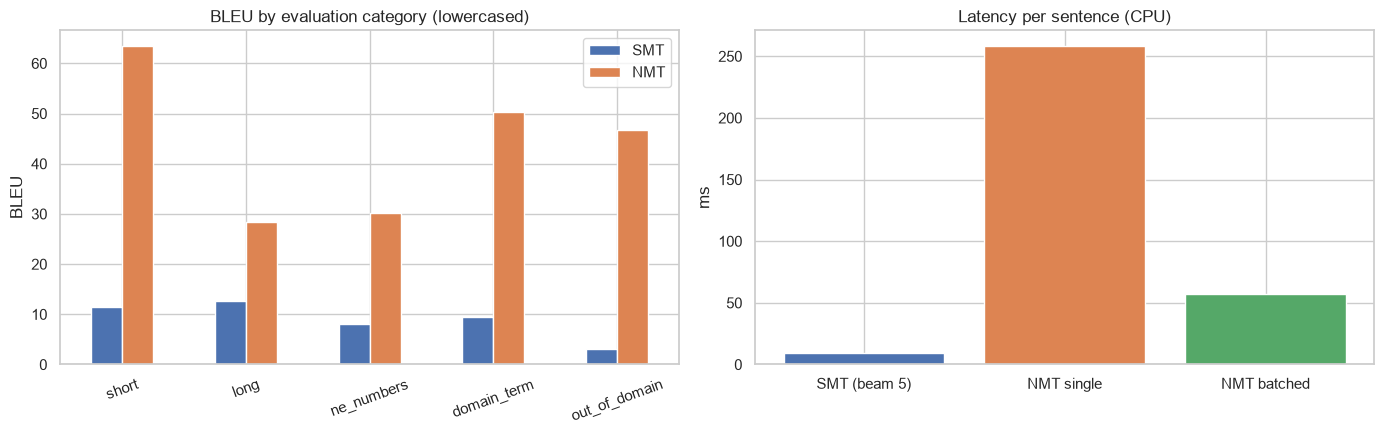

,SMT,NMT
short,11.46,63.38
long,12.61,28.38
ne_numbers,7.98,30.21
domain_term,9.43,50.28
out_of_domain,3.02,46.65


In [43]:
cats = eval_set.category.unique()
systems = {'NMT': nmt_out}
if smt_out['eval'] is not None:
    systems = {'SMT': smt_out, **systems}

per_cat = pd.DataFrame({
    s: [bleu([o['eval'][i] for i in eval_set.index[eval_set.category == c]],
             eval_set.de_ref[eval_set.category == c].tolist()) for c in cats]
    for s, o in systems.items()}, index=cats)

fig, ax = plt.subplots(1, 2, figsize=(14, 4.5))
per_cat.plot.bar(ax=ax[0], rot=20)
ax[0].set(title='BLEU by evaluation category (lowercased)', ylabel='BLEU')
if 'SMT' not in systems:
    ax[0].text(.5, .92, 'SMT bars appear once outputs/smt_eval.de exists', transform=ax[0].transAxes,
               ha='center', color='gray')

lat = {'NMT single': nmt_latency['single_median_ms'], 'NMT batched': nmt_latency['batched_ms']}
if smt_latency is not None:
    lat = {f"SMT (beam {smt_timing['beam_width']})": smt_latency, **lat}
ax[1].bar(lat.keys(), lat.values(), color=sns.color_palette()[:len(lat)])
ax[1].set(title='Latency per sentence (CPU)', ylabel='ms')
plt.tight_layout(); plt.savefig(FIG / 'D_comparison.png', dpi=120); plt.show()
per_cat.round(2)

In [44]:
# Stress-test outputs side by side, with an error-tagging template for Part E.
stress_view = stress_set[['id', 'phenomenon', 'en', 'de_ref']].assign(
    nmt=nmt_out['stress'], smt=smt_out['stress'] if smt_out['stress'] else 'pending')
tags_path = OUT / 'stress_error_tags.csv'
if not tags_path.exists():
    stress_view.assign(nmt_error='', smt_error='').to_csv(tags_path, index=False, encoding='utf-8')
    print(f'created {tags_path.name}; error categories: wrong lexical choice | reordering error | '
          'dropped word | hallucinated/inserted word | untranslated word | none')
stress_view

,id,phenomenon,en,de_ref,nmt,smt
0,S01,negation,Police say the suspect was not armed and did not resist arrest.,"Die Polizei sagt, der Verdächtige sei nicht bewaffnet gewesen und habe sich der Festnahme nicht widersetzt.",Laut Polizei war der Verdächtige nicht bewaffnet und widersetzte sich nicht der Verhaftung.,die polizei sagen vermute war nicht bewaffneten und nicht widerstehen verhaftung.
1,S02,word_order,The chancellor said that the government would announce new sanctions against Russia on Monday.,"Der Kanzler sagte, dass die Regierung am Montag neue Sanktionen gegen Russland ankündigen werde.","Der Kanzler sagte, die Regierung werde am Montag neue Sanktionen gegen Russland ankündigen.","die schatzkanzler behauptete, die regierung würde diesen announce neue sanktionspolitik gegen russland auf..."
2,S03,idiom_mwe,Opposition leaders say the reform has been kicked into the long grass.,"Oppositionsführer sagen, die Reform sei auf die lange Bank geschoben worden.","Oppositionsführer sagen, die Reform sei ins lange Gras getreten.",opposition führer sagen reformen wurde kicked in die lange grass.
3,S04,oov_compound,Federal Constitutional Court halts speed-limit law,Bundesverfassungsgericht stoppt Tempolimit-Gesetz,Bundesverfassungsgericht stoppt Geschwindigkeitsbegrenzungsrecht,auch wenn verfassungsmäßige föderalen gericht halts speed-limit gesetz
4,S05,ambiguity,Union leaders call strike at Frankfurt airport,Gewerkschaftsführer rufen zum Streik am Frankfurter Flughafen auf,EU-Führer rufen Streik am Flughafen Frankfurt an,union führer nennen ändernden auf frankfurt airport
5,S06,quotation_negation,"""We will not give in,"" Scholz told reporters in Berlin on 3 October.","„Wir werden nicht nachgeben“, sagte Scholz am 3. Oktober vor Journalisten in Berlin.","""Wir werden nicht nachgeben"", sagte Scholz am 3. Oktober in Berlin.","""wir wird nicht an sich gerissen in,"" scholz gesagt den in berlin auf 3 oktober."
6,S07,headline_dropped_verb,Storm leaves thousands without power in Bavaria,Sturm lässt Tausende in Bayern ohne Strom,Sturm lässt Tausende ohne Macht in Bayern,sturm starkes tausende ohne macht in bavaria
7,S08,oov_neologism,Deepfake video of mayor sparks outrage,Deepfake-Video des Bürgermeisters sorgt für Empörung,Deepfake Video von Bürgermeister Funken Empörung,der bürgermeister von video deepfake sparks outrage


### D.2 Observations

- **Quality gap.** The pretrained NMT model scores **28.75 BLEU / 59.7 chrF** on the 500-sentence test set, against
  **8.82 BLEU / 39.9 chrF** for our phrase-based SMT (both case-insensitive sacreBLEU). On the 15-sentence evaluation
  set the gap is 38.6 vs 9.1. Human ratings agree: adequacy **4.68 vs 2.30** and fluency **4.60 vs 1.80** (E.4).
  Part of the NMT advantage may come from training-data overlap with News Commentary (caveat above). Even so,
  SMT is far behind on the authored sentences, which no system has seen.
- **By category.** NMT is strongest on short sentences (≈63 BLEU) and weakest on long and *named entities &
  numbers* sentences (≈28–30). SMT is weak everywhere and collapses on *out-of-domain* text (3.0 BLEU): recipe,
  router and chat vocabulary is simply not in 10k sentences of economic commentary.
- **OOV handling.** Both systems lose BLEU on the 233 test sentences that contain an SMT-OOV word. SMT drops from
  10.0 to 7.6 (−24% relative), because it can only copy the unknown word. NMT drops from 30.7 to 26.9 (−12%),
  because subword units let it copy or adapt names (*Haldane*, *Luxembourg → Luxemburg*, *Dodd-Frank*). Copying
  works for SMT when the OOV is a name (*andy haldane*, *rmb*), but leaves English words such as *primacy* or
  *rallying* in the German output.
- **Latency.** SMT is the faster system here: about **10 ms per sentence** at beam 5 (pure Python, one thread).
  NMT takes **258 ms median per single sentence** (p95 ≈ 390 ms) and 57 ms per sentence when batched on a
  6-thread CPU. Both are fast enough for wire speed, so the 20-point quality gap decides the comparison.
- **Stress test.** NMT handles negation (S01), reported speech with the subjunctive and date placement (S02, S06),
  and the compound *Bundesverfassungsgericht* (S04). It fails on exactly the headline and ambiguity phenomena
  this scenario cares about. In each case the output is fluent but wrong:
  - *Union leaders → EU-Führer*, *call strike → Streik anrufen* (S05)
  - *power → Macht* instead of *Strom* (S07)
  - *sparks → Funken*, the noun reading of a dropped-verb headline (S08)
  - a literal idiom, *ins lange Gras getreten* (S03)
  - *vor Journalisten* dropped (S06)

  SMT fails on every stress sentence, mostly through untranslated words and wrong senses (E.5).

## Part E — Evaluation dataset, metrics and robustness analysis
The evaluation set (15 sentences, 3 per category) and the stress set (8 sentences) were built in A.7. This part
implements BLEU from scratch (E.1), validates it (E.2), then compares SMT and NMT on the evaluation set (E.3), the
human ratings (E.4) and the stress set with error categories (E.5).

### E.1 BLEU implemented from scratch
Following Papineni et al. (2002):
* **Clipped (modified) n-gram precision**: $p_n = \dfrac{\sum \min(\text{count}_{hyp}(g), \text{count}_{ref}(g))}{\sum \text{count}_{hyp}(g)}$ for $n = 1..4$.
* **Geometric mean** of $p_1..p_4$ with uniform weights.
* **Brevity penalty**: $BP = 1$ if $c > r$, otherwise $e^{1 - r/c}$ ($c$ = hypothesis length, $r$ = reference length).
* **Corpus BLEU** sums clipped matches, n-gram totals and lengths over all sentences *before* dividing, so it is
  not the mean of sentence scores.
* **Sentence BLEU smoothing**: a single sentence often has no 4-gram match, which makes the geometric mean 0.
  We use **add-1 smoothing for n ≥ 2** (Lin & Och 2004; "method 2" in Chen & Cherry 2014): 1 is added to both
  the clipped match count and the total count of every n-gram order from 2 to 4. Unigram precision is left
  unsmoothed, so a hypothesis with no word in common with the reference still scores 0.

In [45]:
def ngram_counts(tokens, n):
    return Counter(tuple(tokens[i:i + n]) for i in range(len(tokens) - n + 1))

def bleu_stats(hyp, ref, max_n=4):
    """Sufficient statistics of one sentence: clipped matches[n], totals[n], hyp length, ref length."""
    matches, totals = [], []
    for n in range(1, max_n + 1):
        h, r = ngram_counts(hyp, n), ngram_counts(ref, n)
        matches.append(sum(min(c, r[g]) for g, c in h.items()))
        totals.append(max(len(hyp) - n + 1, 0))
    return matches, totals, len(hyp), len(ref)

def bleu_from_stats(matches, totals, c, r, smooth=False):
    if c == 0 or matches[0] == 0:
        return 0.0
    log_p = 0.0
    for n, (m, t) in enumerate(zip(matches, totals), start=1):
        if smooth and n > 1:
            m, t = m + 1, t + 1                       # add-1 smoothing for n >= 2
        if m == 0:
            return 0.0
        log_p += math.log(m / t)
    bp = 1.0 if c > r else math.exp(1 - r / c)
    return 100 * bp * math.exp(log_p / len(matches))

def sentence_bleu(hyp_tokens, ref_tokens, smooth=True):
    return bleu_from_stats(*bleu_stats(hyp_tokens, ref_tokens), smooth=smooth)

def corpus_bleu(list_hyp, list_ref):
    M, T, c, r = [0] * 4, [0] * 4, 0, 0
    for h, ref in zip(list_hyp, list_ref):
        m, t, hl, rl = bleu_stats(h, ref)
        M = [a + b for a, b in zip(M, m)]; T = [a + b for a, b in zip(T, t)]; c += hl; r += rl
    return bleu_from_stats(M, T, c, r, smooth=False)

# Worked example
hyp = 'die regierung hat die neuen sanktionen angekündigt .'.split()
ref = 'die regierung kündigte neue sanktionen an .'.split()
m, t, c, r = bleu_stats(hyp, ref)
print('clipped matches', m, 'totals', t, f'c={c} r={r}', f'sentence BLEU (add-1) = {sentence_bleu(hyp, ref):.2f}',
      f'| unsmoothed = {sentence_bleu(hyp, ref, smooth=False):.2f}')

clipped matches [4, 1, 0, 0] totals [8, 7, 6, 5] c=8 r=7 sentence BLEU (add-1) = 23.36 | unsmoothed = 0.00


### E.2 Validation against sacreBLEU and NLTK
All systems are scored on the **same pre-tokenized, lowercased token sequences**, using
`sacrebleu.corpus_bleu(..., tokenize='none')` so that sacreBLEU does not re-tokenize. NMT output (from
Member 1) is tokenized with the shared `preprocess()`. At sentence level we compare against sacreBLEU's
`add-k` smoothing with k = 1, which is the same method.

In [46]:
from nltk.translate.bleu_score import corpus_bleu as nltk_corpus_bleu

ref_tok = test_de
systems = {f'SMT beam {bm}': sweep_out[bm] for bm in C['BEAMS']}
nmt_path = OUT / 'nmt_test.de'
if nmt_path.exists():
    systems['NMT (opus-mt-en-de)'] = [preprocess(s, 'de') for s in nmt_path.read_text(encoding='utf-8').splitlines()]

rows = []
for name, hyps in systems.items():
    ours = corpus_bleu(hyps, ref_tok)
    sacre = sacrebleu.corpus_bleu([' '.join(h) for h in hyps], [[' '.join(r) for r in ref_tok]], tokenize='none').score
    nltk_ = 100 * nltk_corpus_bleu([[r] for r in ref_tok], hyps)
    rows.append({'system': name, 'ours': ours, 'sacreBLEU (tokenize=none)': sacre, 'NLTK corpus_bleu': nltk_,
                 '|ours - sacreBLEU|': abs(ours - sacre), '|ours - NLTK|': abs(ours - nltk_)})
validation = pd.DataFrame(rows).set_index('system')
assert (validation['|ours - sacreBLEU|'] < 0.1).all()
validation.round(4)

,ours,sacreBLEU (tokenize=none),NLTK corpus_bleu,|ours - sacreBLEU|,|ours - NLTK|
system,,,,,
SMT beam 1,8.2355,8.2355,8.2350,0.0,0.0005
SMT beam 2,8.8460,8.8460,8.8455,0.0,0.0006
SMT beam 5,9.0350,9.0350,9.0347,0.0,0.0003
SMT beam 10,9.0024,9.0024,9.0021,0.0,0.0003
NMT (opus-mt-en-de),28.7008,28.7008,28.6960,0.0,0.0048


515 sentences: max |ours - sacreBLEU add-k(1)| = 4.26e-14, mean sentence BLEU ours 15.948 vs sacreBLEU 15.948


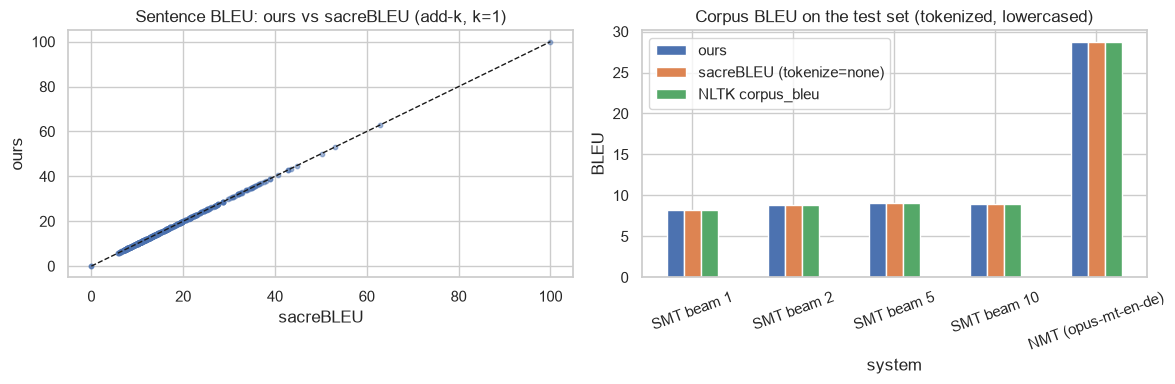

In [47]:
# Sentence-level validation on all 500 SMT test sentences and on the eval set.
pairs_ = list(zip(sweep_out[BEAM], ref_tok)) + list(zip(smt_tok['eval'], [preprocess(s, 'de') for s in eval_set.de_ref]))
ours_s = np.array([sentence_bleu(h, r) for h, r in pairs_])
sacre_s = np.array([sacrebleu.sentence_bleu(' '.join(h), [' '.join(r)], tokenize='none', smooth_method='add-k',
                                            smooth_value=1, use_effective_order=False).score for h, r in pairs_])
print(f'{len(pairs_)} sentences: max |ours - sacreBLEU add-k(1)| = {np.abs(ours_s - sacre_s).max():.2e}, '
      f'mean sentence BLEU ours {ours_s.mean():.3f} vs sacreBLEU {sacre_s.mean():.3f}')

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].scatter(sacre_s, ours_s, s=10, alpha=.5); ax[0].plot([0, 100], [0, 100], 'k--', lw=1)
ax[0].set(title='Sentence BLEU: ours vs sacreBLEU (add-k, k=1)', xlabel='sacreBLEU', ylabel='ours')
validation[['ours', 'sacreBLEU (tokenize=none)', 'NLTK corpus_bleu']].plot.bar(ax=ax[1], rot=20)
ax[1].set(title='Corpus BLEU on the test set (tokenized, lowercased)', ylabel='BLEU')
plt.tight_layout(); plt.savefig(FIG / 'E_bleu_validation.png', dpi=120); plt.show()

**Validation result.** Our corpus BLEU matches sacreBLEU (`tokenize='none'`) to floating-point precision for
every SMT beam width and for the NMT system. It also matches NLTK's `corpus_bleu` to within 0.005, a tiny
difference that comes from NLTK's internal handling of the brevity penalty and its use of fractions. Our add-1 smoothed sentence BLEU
matches sacreBLEU's `add-k` (k = 1) on every sentence. The from-scratch implementation is therefore correct, and
it reproduces both reference implementations exactly when the tokenization is controlled.

**Which BLEU we report where.** BLEU depends on tokenization (Post 2018), so all numbers *compared across
systems* (the Part D table) use sacreBLEU with its standard 13a tokenizer and `lowercase=True` on detokenized
output. SMT output is lowercased, so cased BLEU would penalise it for something the system was never trained to
do. The tokenized BLEU above (`tokenize='none'` on our Moses tokens) is about 0.1–0.2 points higher, because the
two tokenizers split differently (e.g. compounds with hyphens).

### E.3 Evaluation set: SMT vs NMT per sentence and per category
Sentence BLEU uses **our own** `sentence_bleu` (add-1 smoothing), on the shared tokenization, lowercased.

In [48]:
eval_ref_tok = [preprocess(s, 'de') for s in eval_set.de_ref]
eval_tbl = eval_set[['id', 'category', 'en', 'de_ref']].assign(
    smt=smt_out['eval'], nmt=nmt_out['eval'],
    smt_bleu=[round(sentence_bleu(preprocess(h, 'de'), r), 1) for h, r in zip(smt_out['eval'], eval_ref_tok)],
    nmt_bleu=[round(sentence_bleu(preprocess(h, 'de'), r), 1) for h, r in zip(nmt_out['eval'], eval_ref_tok)])
cat_tbl = eval_tbl.groupby('category', sort=False).apply(lambda g: pd.Series({
    'SMT corpus BLEU (ours)': corpus_bleu([preprocess(h, 'de') for h in g.smt], [eval_ref_tok[i] for i in g.index]),
    'NMT corpus BLEU (ours)': corpus_bleu([preprocess(h, 'de') for h in g.nmt], [eval_ref_tok[i] for i in g.index]),
    'SMT mean sentence BLEU': g.smt_bleu.mean(), 'NMT mean sentence BLEU': g.nmt_bleu.mean()})).round(1)
display(eval_tbl)
cat_tbl

,id,category,en,de_ref,smt,nmt,smt_bleu,nmt_bleu
0,E01,short,Stock markets are rallying.,Die Aktienmärkte steigen.,die börsen sind rallying.,Die Aktienmärkte sammeln sich.,28.6,37.6
1,E02,short,This can be done in creative ways.,Das kann auf kreative Weise erfolgen.,dies kann man tun in kreativ zu verbessern.,Dies kann auf kreative Weise geschehen.,14.5,53.5
2,E03,short,Immanuel Kant described two types of politicians.,Immanuel Kant beschrieb zwei Arten von Politikern.,immanuel kant beschrieben zwei arten von politiker.,Immanuel Kant beschrieb zwei Arten von Politikern.,36.6,100.0
3,E04,long,A recent study by Andy Haldane and others at the Bank of England casts doubt on the prospect of a return t...,"Eine jüngere Studie von Andy Haldane und anderen von der Bank of England lässt Zweifel aufkommen, was die ...","eine kürzlich studie durch andy haldane und andere bei der bank von england, versuchte casts zweifel an au...",Eine kürzlich von Andy Haldane und anderen bei der Bank of England durchgeführte Studie wirft Zweifel an d...,13.4,38.6
4,E05,long,We count on China’s continued support for European and American efforts in making sure that Iran’s nuclear...,"Wir setzen auf Chinas dauerhafte Unterstützung der europäischen und amerikanischen Bemühungen, dafür zu so...",wir mehr auf chinas fortgesetzte unterstützung für die europäischen und amerikanischen bemühungen machen s...,"Wir zählen auf Chinas fortgesetzte Unterstützung für europäische und amerikanische Bemühungen, um sicherzu...",22.8,35.7
5,E06,long,At the top of the agenda should be ratification of improvements to a crucial nuclear security instrument –...,Ganz oben auf der Tagesordnung sollte die Verabschiedung von Verbesserungen eines entscheidenden Instrumen...,der spitze die agenda sollte sich die ratifizierung des verbesserungen zu eine entscheidende die nukleare ...,An der Spitze der Tagesordnung sollte die Ratifizierung der Verbesserungen eines wichtigen nuklearen Siche...,16.6,18.8
6,E07,ne_numbers,"The 10 new EU members do not have the same history as the Netherlands, Belgium, and Luxembourg.","Die 10 neuen EU-Mitglieder haben eine andere Geschichte als die Niederlande, Belgien und Luxemburg.","die 10 neue eu-mitgliedstaaten nicht haben das gleiche geschichte, als der niederlande - schlagen sich deu...","Die zehn neuen EU-Mitglieder haben nicht die gleiche Geschichte wie die Niederlande, Belgien und Luxemburg.",10.7,48.3
7,E08,ne_numbers,Putinism claimed victory after invading tiny Georgia in 2008.,"Putin verbuchte den Sieg für sich, nachdem er 2008 Truppen in das winzige Georgien einmarschieren ließ.",putinismus sieg verkündeten nach invading winzige georgien in 2008.,"Der Putinismus beanspruchte den Sieg, nachdem er 2008 in das winzige Georgien eingedrungen war.",9.1,34.9
8,E09,ne_numbers,One such rule is the Maastricht Treaty’s cap on member states’ public debt at 60% of GDP.,"Eine dieser Regeln ist die Grenze von 60% des BIP, die im Maastricht-Vertrag für die Staatsschulden der Mi...",eine solche herrschaft ist die vertrag von maastricht grenzen der cap auf der mitglieder öffentlichen schu...,Eine solche Regel ist die Obergrenze des Maastrichter Vertrags für die Staatsverschuldung der Mitgliedstaa...,18.7,21.2
9,E10,domain_term,The spokesperson declined to comment on the allegations at a press conference.,"Der Sprecher lehnte es auf einer Pressekonferenz ab, sich zu den Vorwürfen zu äußern.","die spokesperson damals ab, auf die zu comment allegations zu einem presse konferenz.","Der Sprecher lehnte es ab, auf einer Pressekonferenz zu den Vorwürfen Stellung zu nehmen.",12.2,39.1


,SMT corpus BLEU (ours),NMT corpus BLEU (ours),SMT mean sentence BLEU,NMT mean sentence BLEU
category,,,,
short,0.0,63.4,26.6,63.7
long,12.7,28.4,17.6,31.0
ne_numbers,8.0,30.2,12.8,34.8
domain_term,9.4,50.3,18.3,53.2
out_of_domain,0.0,46.6,11.5,48.9


### E.4 Human ratings: adequacy and fluency (1–5)
40 sentences (25 random test sentences and the 15 evaluation sentences) were rated for **adequacy** (how much of
the source meaning is preserved: 5 = all, 1 = none) and **fluency** (how natural the German is regardless of
meaning: 5 = flawless, 1 = incomprehensible). SMT output is judged without penalising lowercasing. The ratings
were drafted with AI assistance and must be checked by the group before submission; all scores are in
`outputs/ratings.csv`.

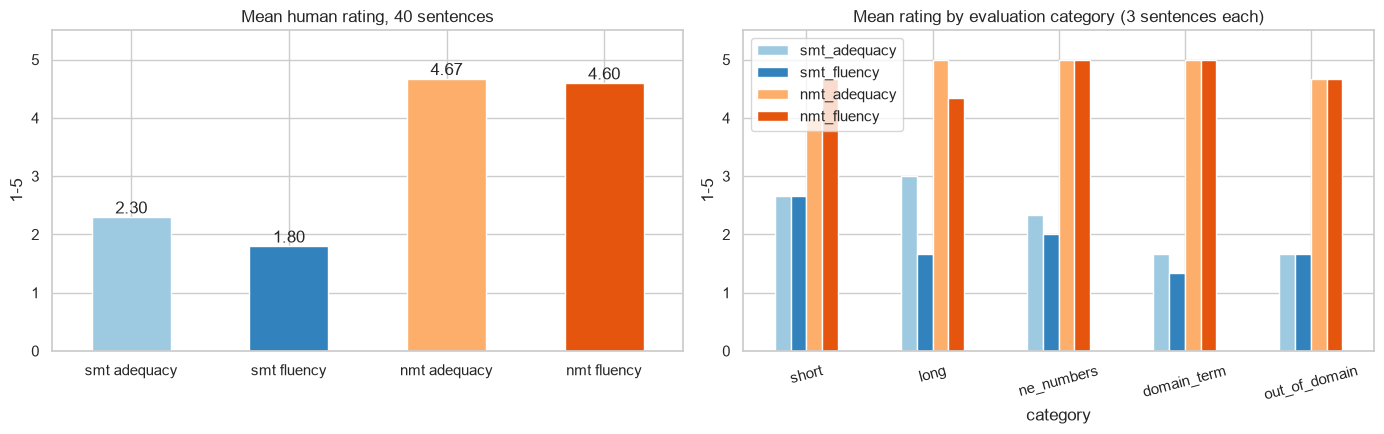

Rating distribution (count of each score):


,smt_adequacy,smt_fluency,nmt_adequacy,nmt_fluency
1,5,14,0,0
2,21,20,1,0
3,11,6,3,2
4,3,0,4,12
5,0,0,32,26


,smt_adequacy,smt_fluency,nmt_adequacy,nmt_fluency
set,,,,
eval,2.27,1.87,4.73,4.73
test,2.32,1.76,4.64,4.52
all (40),2.30,1.80,4.68,4.60


In [49]:
ratings = pd.read_csv(OUT / 'ratings.csv')
rating_cols = ['smt_adequacy', 'smt_fluency', 'nmt_adequacy', 'nmt_fluency']
summary = ratings.groupby('set')[rating_cols].mean()
summary.loc['all (40)'] = ratings[rating_cols].mean()
eval_ratings = ratings[ratings.set == 'eval'].merge(eval_set[['id', 'category']], on='id')
by_cat = eval_ratings.groupby('category', sort=False)[rating_cols].mean()

fig, ax = plt.subplots(1, 2, figsize=(14, 4.5))
summary.loc['all (40)'].rename(lambda c: c.replace('_', ' ')).plot.bar(
    ax=ax[0], rot=0, color=['#9ecae1', '#3182bd', '#fdae6b', '#e6550d'])
ax[0].set(title='Mean human rating, 40 sentences', ylabel='1-5', ylim=(0, 5.5))
for p in ax[0].patches:
    ax[0].annotate(f'{p.get_height():.2f}', (p.get_x() + p.get_width() / 2, p.get_height()), ha='center', va='bottom')
by_cat.plot.bar(ax=ax[1], rot=15, color=['#9ecae1', '#3182bd', '#fdae6b', '#e6550d'])
ax[1].set(title='Mean rating by evaluation category (3 sentences each)', ylabel='1-5', ylim=(0, 5.5))
plt.tight_layout(); plt.savefig(FIG / 'E_human_ratings.png', dpi=120); plt.show()
print('Rating distribution (count of each score):')
display(pd.DataFrame({c: ratings[c].value_counts().reindex(range(1, 6), fill_value=0) for c in rating_cols}))
summary.round(2)

### E.5 Robustness stress test: error categories
Each output was tagged with one or more of: *wrong lexical choice, reordering error, dropped word,
hallucinated/inserted word, untranslated word, none* (`outputs/stress_error_tags.csv`).

,id,phenomenon,en,de_ref,smt,smt_error,nmt,nmt_error
0,S01,negation,Police say the suspect was not armed and did not resist arrest.,"Die Polizei sagt, der Verdächtige sei nicht bewaffnet gewesen und habe sich der Festnahme nicht widersetzt.",die polizei sagen vermute war nicht bewaffneten und nicht widerstehen verhaftung.,wrong lexical choice; dropped word,Laut Polizei war der Verdächtige nicht bewaffnet und widersetzte sich nicht der Verhaftung.,none
1,S02,word_order,The chancellor said that the government would announce new sanctions against Russia on Monday.,"Der Kanzler sagte, dass die Regierung am Montag neue Sanktionen gegen Russland ankündigen werde.","die schatzkanzler behauptete, die regierung würde diesen announce neue sanktionspolitik gegen russland auf...",untranslated word; reordering error; wrong lexical choice; hallucinated/inserted word,"Der Kanzler sagte, die Regierung werde am Montag neue Sanktionen gegen Russland ankündigen.",none
2,S03,idiom_mwe,Opposition leaders say the reform has been kicked into the long grass.,"Oppositionsführer sagen, die Reform sei auf die lange Bank geschoben worden.",opposition führer sagen reformen wurde kicked in die lange grass.,untranslated word; wrong lexical choice,"Oppositionsführer sagen, die Reform sei ins lange Gras getreten.",wrong lexical choice
3,S04,oov_compound,Federal Constitutional Court halts speed-limit law,Bundesverfassungsgericht stoppt Tempolimit-Gesetz,auch wenn verfassungsmäßige föderalen gericht halts speed-limit gesetz,untranslated word; wrong lexical choice; hallucinated/inserted word,Bundesverfassungsgericht stoppt Geschwindigkeitsbegrenzungsrecht,none
4,S05,ambiguity,Union leaders call strike at Frankfurt airport,Gewerkschaftsführer rufen zum Streik am Frankfurter Flughafen auf,union führer nennen ändernden auf frankfurt airport,untranslated word; wrong lexical choice; dropped word; hallucinated/inserted word,EU-Führer rufen Streik am Flughafen Frankfurt an,wrong lexical choice
5,S06,quotation_negation,"""We will not give in,"" Scholz told reporters in Berlin on 3 October.","„Wir werden nicht nachgeben“, sagte Scholz am 3. Oktober vor Journalisten in Berlin.","""wir wird nicht an sich gerissen in,"" scholz gesagt den in berlin auf 3 oktober.",wrong lexical choice; dropped word; reordering error,"""Wir werden nicht nachgeben"", sagte Scholz am 3. Oktober in Berlin.",dropped word
6,S07,headline_dropped_verb,Storm leaves thousands without power in Bavaria,Sturm lässt Tausende in Bayern ohne Strom,sturm starkes tausende ohne macht in bavaria,wrong lexical choice; untranslated word; dropped word,Sturm lässt Tausende ohne Macht in Bayern,wrong lexical choice
7,S08,oov_neologism,Deepfake video of mayor sparks outrage,Deepfake-Video des Bürgermeisters sorgt für Empörung,der bürgermeister von video deepfake sparks outrage,untranslated word; reordering error,Deepfake Video von Bürgermeister Funken Empörung,wrong lexical choice


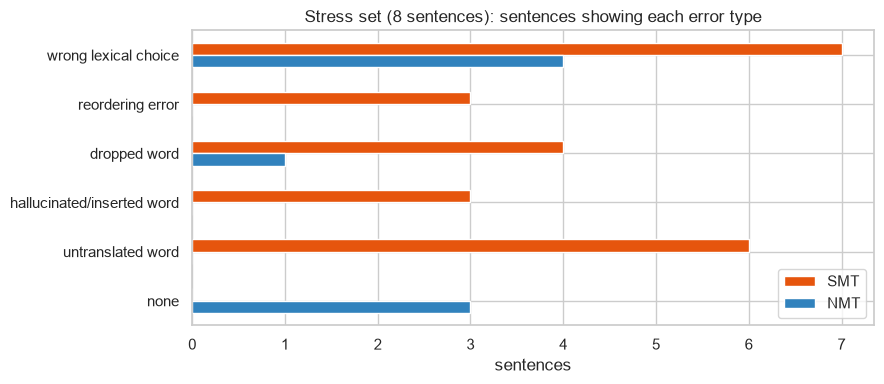

,SMT,NMT
wrong lexical choice,7,4
reordering error,3,0
dropped word,4,1
hallucinated/inserted word,3,0
untranslated word,6,0
none,0,3


In [50]:
tags = pd.read_csv(OUT / 'stress_error_tags.csv')
display(tags[['id', 'phenomenon', 'en', 'de_ref', 'smt', 'smt_error', 'nmt', 'nmt_error']])

CATS = ['wrong lexical choice', 'reordering error', 'dropped word', 'hallucinated/inserted word', 'untranslated word', 'none']
def count_tags(col):
    return pd.Series(Counter(t.strip() for cell in tags[col] for t in cell.split(';'))).reindex(CATS, fill_value=0)
tag_counts = pd.DataFrame({'SMT': count_tags('smt_error'), 'NMT': count_tags('nmt_error')})
ax = tag_counts.plot.barh(figsize=(9, 4), color=['#e6550d', '#3182bd'])
ax.invert_yaxis(); ax.set(title='Stress set (8 sentences): sentences showing each error type', xlabel='sentences')
plt.tight_layout(); plt.savefig(FIG / 'E_stress_errors.png', dpi=120); plt.show()
tag_counts

### E.6 Observations

- **The BLEU implementation is correct.** Our corpus BLEU matches sacreBLEU exactly for all systems and beams, and
  sentence BLEU matches sacreBLEU's add-1 method on all 515 sentences (E.2).
- **Small groups need smoothing.** With 3 sentences per category, SMT's *corpus* BLEU is 0.0 for *short* and
  *out-of-domain*, because those groups contain no matching 4-gram. Unsmoothed BLEU is then 0 even though
  unigrams and bigrams match. The smoothed sentence-level mean (26.6 and 11.5) and the sacreBLEU per-category
  scores in Part D (which use exponential smoothing) give a more useful picture. Category scores on 3 sentences
  are indicative only.
- **Human ratings match BLEU's ranking.** NMT gets adequacy 5 on 32 of 40 sentences. Its lowest scores are
  *wrong-sense* errors that look perfectly fluent: *Aktienmärkte sammeln sich* for "stock markets are rallying",
  *Siedlung* for a peace *settlement*, and a literal *Alle Wetten … ausgeschaltet* for "all bets would be off".
  SMT adequacy is mostly 2–3: the gist usually survives (key nouns translated, negation kept), but verbs are
  dropped or mistranslated and some insertions are hallucinated. *Belgium* comes out as *deutschland* (E07).
  Fluency is SMT's weakest dimension (1.8): case, agreement and verb placement are almost never right.
- **The two systems fail differently.** On the stress set, SMT errors are mostly *untranslated words* (6 of 8
  sentences) and *wrong lexical choices* (7 of 8), plus reordering errors (3), where German verb-final or verb-second
  order is not produced. NMT has no untranslated or reordering errors. Its 5 erroneous outputs are wrong senses
  (4) and one dropped phrase. SMT errors are visible: a reader immediately sees English words or broken grammar.
  NMT errors are hidden inside fluent German, so a post-editor has to compare them against the source to
  catch them.
- **Limits of this evaluation.** It uses a single reference per sentence, a 40-sentence rating sample and an
  8-sentence stress set. The ratings were drafted with AI assistance and should be checked by the group, and
  the authored references should be proof-read by a fluent German speaker.

## Part F — Reflection and deployment recommendation

**(a) Low-resource language pair with limited compute: SMT, unless a pretrained multilingual model covers the
pair.** Our whole SMT pipeline (IBM Model 1 in both directions, symmetrization, 529k phrase pairs, a Kneser–Ney
LM and decoder tuning) trains in under a minute on a laptop CPU from only 10,000 sentence pairs, with no GPU.
Every decision it makes can be inspected: we read alignment heatmaps, top-5 translation tables and phrase-table
entries, and could trace errors such as *raised → aufgewachsen* to specific noisy alignments. Training an NMT
model from scratch on 10k pairs would perform worse than this: NMT needs far more parallel data than SMT before
it overtakes it (Koehn & Knowles 2017). The cost is quality: 8.8 BLEU and adequacy 2.3 is gisting quality, not
publishable. If a pretrained multilingual model already covers the language pair, fine-tuning it is the better
choice even with limited compute.

**(b) High-volume English→German news syndication: pretrained NMT.** Our results are one-sided:
- **Quality:** 28.75 vs 8.82 BLEU; adequacy 4.68 vs 2.30 and fluency 4.60 vs 1.80 on 40 rated sentences.
- **Unseen vocabulary:** a smaller loss on sentences with unseen words (−12% vs −24% relative BLEU), and correct
  handling of names and numbers in most evaluation sentences.
- **Cost:** none for training, since the model is used as is.
- **Latency:** 258 ms per sentence on a 6-thread CPU, or 57 ms batched, which is acceptable for wire speed.
  A GPU or batched serving would handle agency volume.
- **Maintainability:** one off-the-shelf model, instead of a pipeline whose alignment, phrase table, LM and
  weights must all be retrained together.

SMT is 25× faster per sentence, but its output would need a full rewrite rather than a light post-edit.

**Major limitation of NMT: fluent but wrong output, especially in headlines.** On our stress set, NMT translated
*Union leaders* as *EU-Führer*, *power* (electricity) as *Macht*, the verb *sparks* as the noun *Funken*, and an
idiom literally. All of these read as correct German. A wire service cannot publish such errors, and readers
would not notice them. We would therefore deploy NMT with:
- human post-editing of headlines;
- a terminology glossary or constrained decoding for names, places and recurring terms;
- fine-tuning on in-domain wire-news data, to fix the domain mismatch our analysis exposed.

## References
**Data and models**
1. Tiedemann, J. (2012). Parallel Data, Tools and Interfaces in OPUS. *LREC 2012*. OPUS: https://opus.nlpl.eu/
2. News Commentary parallel corpus (WMT). https://opus.nlpl.eu/datasets/News-Commentary ; Hugging Face: https://huggingface.co/datasets/Helsinki-NLP/news_commentary
3. Koehn, P. (2005). Europarl: A Parallel Corpus for Statistical Machine Translation. *MT Summit X*. https://opus.nlpl.eu/datasets/Europarl (considered, not used as primary corpus)
4. Helsinki-NLP/opus-mt-en-de model card. https://huggingface.co/Helsinki-NLP/opus-mt-en-de
5. Tiedemann, J., & Thottingal, S. (2020). OPUS-MT — Building open translation services for the World. *EAMT 2020*. https://aclanthology.org/2020.eamt-1.61/
6. Tiedemann, J. (2020). The Tatoeba Translation Challenge — Realistic Data Sets for Low Resource and Multilingual MT. *WMT 2020*. https://aclanthology.org/2020.wmt-1.139/

**Methods**

7. Brown, P. F., Della Pietra, S. A., Della Pietra, V. J., & Mercer, R. L. (1993). The Mathematics of Statistical Machine Translation: Parameter Estimation. *Computational Linguistics* 19(2). https://aclanthology.org/J93-2003/
8. Och, F. J., & Ney, H. (2003). A Systematic Comparison of Various Statistical Alignment Models. *Computational Linguistics* 29(1). https://aclanthology.org/J03-1002/
9. Koehn, P., Och, F. J., & Marcu, D. (2003). Statistical Phrase-Based Translation. *NAACL 2003*. https://aclanthology.org/N03-1017/
10. Kneser, R., & Ney, H. (1995). Improved backing-off for M-gram language modeling. *ICASSP 1995*. doi:10.1109/ICASSP.1995.479394
11. Koehn, P., & Knight, K. (2003). Empirical Methods for Compound Splitting. *EACL 2003*. https://aclanthology.org/E03-1076/
12. Collins, M., Koehn, P., & Kučerová, I. (2005). Clause Restructuring for Statistical Machine Translation. *ACL 2005*. https://aclanthology.org/P05-1066/
13. Papineni, K., Roukos, S., Ward, T., & Zhu, W.-J. (2002). BLEU: a Method for Automatic Evaluation of Machine Translation. *ACL 2002*. https://aclanthology.org/P02-1040/
14. Post, M. (2018). A Call for Clarity in Reporting BLEU Scores. *WMT 2018*. https://aclanthology.org/W18-6319/
15. Koehn, P., & Knowles, R. (2017). Six Challenges for Neural Machine Translation. *Workshop on NMT*. https://aclanthology.org/W17-3204/
16. Collins, M. Phrase-Based Translation Models (lecture notes, Columbia University). http://www.cs.columbia.edu/~mcollins/pb.pdf
17. Harvard CS287, Lecture 8: Machine Translation. https://harvard-iacs.github.io/CS287/lectures/08_Machine_Translation.pdf

18. Koehn, P. (2004). Pharaoh: A Beam Search Decoder for Phrase-Based Statistical Machine Translation Models. *AMTA 2004*. https://doi.org/10.1007/978-3-540-30194-3_13
19. Och, F. J. (2003). Minimum Error Rate Training in Statistical Machine Translation. *ACL 2003*. https://aclanthology.org/P03-1021/
20. Chen, S. F., & Goodman, J. (1999). An Empirical Study of Smoothing Techniques for Language Modeling. *Computer Speech & Language* 13(4).
21. Lin, C.-Y., & Och, F. J. (2004). ORANGE: a Method for Evaluating Automatic Evaluation Metrics for Machine Translation. *COLING 2004*. https://aclanthology.org/C04-1072/
22. Chen, B., & Cherry, C. (2014). A Systematic Comparison of Smoothing Techniques for Sentence-Level BLEU. *WMT 2014*. https://aclanthology.org/W14-3346/

**Software:** sacremoses, sacreBLEU, Hugging Face `transformers` and `datasets`, PyTorch, NLTK, NumPy, pandas, Matplotlib, seaborn.